# Modelo final de operación de la cuenca del Maule
**ICS2122 · Grupo 13 · Evaluación de una nueva central en el nodo B_Maule**

Este notebook calcula cuánta agua llega al punto donde iría la nueva central (nodo **B_Maule**, el río Maule bajo Loma Alta) durante un año de operación (julio 2026 a junio 2027). Para eso optimiza la operación de toda la cuenca: decide cuánto turbina, vierte y guarda cada central y embalse para **maximizar el ingreso por generación a costo marginal**. Al mismo tiempo cumple las restricciones físicas, el riego y el Convenio de Riego de 1947.

### Cómo usarlo
**Local (VS Code / Jupyter):** dejen los datos en `data/` y ejecuten todas las celdas (ver `README.md`).

**Colab:**
1. Suban al panel de archivos de Colab (ícono de carpeta, a la izquierda) estos 4 archivos: `plpcnfce.dat`, `plpbar.dat`, `po12meses_jul26.xlsx` y `CaudalesHistoricos.xlsx`.
2. Para la licencia de Gurobi, suban también su `gurobi.lic` **o** peguen sus 3 valores WLS en la celda de licencia.
3. Vayan a *Entorno de ejecución → Ejecutar todas*. Al final se descarga `resultados_modelo_final_maule.xlsx`.

### Decisiones del modelo (acordadas por el equipo)
| # | Decisión | Qué usamos | Por qué, en una línea |
|---|---|---|---|
| D1 | Quién optimiza | **Un solo optimizador centralizado** para toda la cuenca | Así opera Chile: el Coordinador (CEN) despacha a mínimo costo del sistema y paga a cada central CMg × energía |
| D2 | Afluentes | **CaudalesHistoricos.xlsx** (65 años) | Trae los 8 nodos de entrada, incluida la Laguna del Maule, y permite elegir años por probabilidad |
| D3 | Escenarios | **Años con Pe 20 / 50 / 90 %**: 1992-93, 1973-74 y 2010-11 | Regla estándar en hidrología: Pe = posición / (n + 1) ordenando el volumen anual |
| D4 | Precios | **CMG. HID. MEDIA para los 3 escenarios** | Separa el efecto del agua del efecto precio (detalle en la sección 4) |
| D5 | Tiempo | **48 semanas × 5 bloques horarios** | El precio cambia mucho dentro de la semana; los embalses mueven agua a los bloques caros |
| D6 | Gasto máximo de riego | **160 m³/s** (200 m³/s como sensibilidad) | Es el desarrollo actual del riego según el Convenio y el Informe 1 |
| D7 | Riego | **Canales obligatorios**, con déficit penalizado | El riego tiene prioridad; si fuera imposible cumplirlo, el modelo lo informa en vez de fallar |
| D8 | Volumen final | **V final ≥ V inicial** en los 4 embalses | Operación cíclica: no se puede "regalar" agua vaciando los embalses al final del año |
| D9 | Filtración de La Invernada | **Constante, calibrada con Ojos de Agua (≈ 11,8 m³/s)** | El Informe 1 la trata como pérdida promedio constante |
| D10 | Convenio | Arts. 2, 3, 4, 5b, 6 y 8 (detalle en la sección 7) | Son las reglas que limitan cuánta agua sale de la Laguna del Maule y de La Invernada |
| D11 | Red | Topología de `plpcnfce.dat` + 3 correcciones del diagrama de conectividad | Algunos vertimientos del PLP no apuntan al nodo correcto |
| D12 | Caso base | **Operación secuencial con objetivo semanal**, con las mismas condiciones de borde y riego sin déficit | Así la comparación aísla el valor de planificar el año completo, sin mezclarlo con vaciar embalses ni dejar riego sin cubrir (sección 9) |
| D13 | Solver y salidas | Gurobi (licencia académica) + verificación independiente + Excel + figuras del informe | La verificación revisa la solución sin confiar en el solver. Sin licencia completa, el mismo modelo se resuelve con HiGHS (sección 0) |

La lectura de `plpcnfce.dat`, las correcciones de la red, la calibración de la filtración y varias reglas del Convenio vienen del Modelo C de Persona 1, adaptadas a un solo optimizador.

## 0. Preparación
Instala `gurobipy` y carga las librerías: `numpy` y `pandas` para los datos, `openpyxl` para leer el Excel del CEN, `matplotlib` para los gráficos y `gurobipy` para el modelo.

In [1]:
try:                                   # en Colab se instala; en local ya viene de requirements.txt
    import gurobipy
except ImportError:
    get_ipython().run_line_magic("pip", "install -q gurobipy highspy")

import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
import gurobipy as gp
from gurobipy import GRB

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("gurobipy", gp.gurobi.version())

gurobipy (13, 0, 3)


In [2]:
ENV = None

### Licencia de Gurobi
La licencia gratuita que trae `pip install gurobipy` solo admite modelos de hasta 2.000 variables, y este modelo tiene unas 16.700. Por eso se usa la **licencia académica WLS** (portal.gurobi.com → Licenses → WLS Academic).

La celda busca un archivo `gurobi.lic` en el panel de archivos. Si no lo encuentra, usa los 3 valores que peguen abajo. **Borren las claves antes de entregar o compartir el notebook.**

In [3]:
import os
WLS = {"WLSACCESSID": "", "WLSSECRET": "", "LICENSEID": ""}   # peguen aquí sus valores si no suben gurobi.lic
if not os.path.exists("/content/gurobi.lic") and all(WLS.values()):
    open("/content/gurobi.lic", "w").write("".join(f"{k}={v}\n" for k, v in WLS.items()))
if os.path.exists("/content/gurobi.lic"):
    os.environ["GRB_LICENSE_FILE"] = "/content/gurobi.lic"
else:
    print("Sin gurobi.lic: suban el archivo o peguen sus valores WLS en esta celda.")


Sin gurobi.lic: suban el archivo o peguen sus valores WLS en esta celda.


### Solver
El modelo se arma siempre con `gurobipy`. Si hay licencia completa de Gurobi se resuelve con Gurobi (así se hizo la corrida oficial). Si solo está la licencia restringida de `pip install gurobipy` (2.000 variables), la función `optimizar` exporta **el mismo modelo** a un archivo MPS y lo resuelve con **HiGHS**, un solver libre. Así cualquiera puede ejecutar el notebook completo sin licencia. Ambos solvers entregan los mismos caudales y volúmenes; solo los casos secuenciales (caso base y miope), que resuelven 48 problemas encadenados con soluciones alternativas, pueden diferir en algunos MUSD de ingreso (ver la nota de la sección 9). Para forzar uno, definan `SOLVER = "gurobi"` o `"highs"` en esta celda.

In [4]:
import tempfile


def licencia_completa():
    """True si Gurobi puede resolver un modelo de más de 2.000 variables."""
    try:
        with gp.Env(params={"OutputFlag": 0}) as env, gp.Model(env=env) as m:
            x = m.addVars(2100)
            m.addConstr(gp.quicksum(x.values()) <= 1)
            m.setObjective(gp.quicksum(x.values()), GRB.MAXIMIZE)
            m.optimize()
        return True
    except gp.GurobiError:
        return False


SOLVER = os.environ.get("SOLVER") or ("gurobi" if licencia_completa() else "highs")
if SOLVER == "highs":
    try:
        import highspy
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "highspy"])
        import highspy
print("Solver:", SOLVER)


class Solucion:
    """Valores de la solución: X(var) equivale a var.X de Gurobi."""
    def __init__(self, valores, gap):
        self.valores, self.gap = valores, gap

    def __call__(self, v):
        return self.valores[v.index]


def optimizar(m):
    """Resuelve el modelo m con el solver elegido y devuelve su solución."""
    if SOLVER == "gurobi":
        m.Params.TimeLimit, m.Params.MIPGap, m.Params.OutputFlag = TIEMPO_MAX, GAP_MIP, 0
        m.optimize()
        if m.SolCount == 0:
            raise RuntimeError(f"Gurobi no encontró solución (estado {m.Status})")
        return Solucion(m.getAttr("X", m.getVars()), m.MIPGap if m.IsMIP else 0.0)
    m.update()
    with tempfile.TemporaryDirectory() as d:
        archivo = os.path.join(d, "modelo.mps")
        m.write(archivo)
        h = highspy.Highs()
        h.setOptionValue("output_flag", False)
        h.setOptionValue("mip_rel_gap", GAP_MIP)
        h.setOptionValue("time_limit", float(TIEMPO_MAX))
        h.readModel(archivo)
        h.run()
    estado = h.getModelStatus()
    if estado not in (highspy.HighsModelStatus.kOptimal, highspy.HighsModelStatus.kTimeLimit):
        raise RuntimeError(f"HiGHS no encontró solución ({h.modelStatusToString(estado)})")
    return Solucion(list(h.getSolution().col_value), float(getattr(h.getInfo(), "mip_gap", 0.0) or 0.0))


Solver: highs


## 1. Archivos de entrada
| Archivo | Para qué se usa |
|---|---|
| `plpcnfce.dat` | Parámetros de cada central y embalse (potencia, rendimiento, volúmenes, a qué nodo va el agua turbinada y la vertida) |
| `plpbar.dat` | Nombre de la barra eléctrica de cada central (para buscar su costo marginal) |
| `po12meses_jul26.xlsx` | Horas de cada bloque (hoja DEMANDA), costos marginales (CMG. HID. MEDIA) y generación de Ojos de Agua (para la filtración) |
| `CaudalesHistoricos.xlsx` | Caudales semanales de 1960 a 2025 en los 8 puntos donde entra agua a la cuenca |

In [5]:
DATA = "data/" if os.path.isdir("data") else ""   # usa data/ local o la carpeta raíz de Colab
ARCHIVOS = ["plpcnfce.dat", "plpbar.dat", "po12meses_jul26.xlsx", "CaudalesHistoricos.xlsx"]
faltan = [f for f in ARCHIVOS if not os.path.exists(DATA + f)]
if faltan:
    raise FileNotFoundError(f"Suban al panel de archivos: {faltan}")
print("Archivos encontrados:", ARCHIVOS)

Archivos encontrados: ['plpcnfce.dat', 'plpbar.dat', 'po12meses_jul26.xlsx', 'CaudalesHistoricos.xlsx']


## 2. Parámetros y decisiones
Todos los números que se pueden cambiar están en esta celda; el resto del código no tiene números escritos a mano.

**Horizonte.** 48 semanas, de julio 2026 a junio 2027, con 4 semanas por mes (algunas de 9 días, como en el pronóstico del CEN). Cada semana tiene 5 bloques horarios. `KAPPA` convierte caudal × horas en volumen: 1 m³/s durante 1 hora son 3.600 m³ = 0,0036 hm³.

**Gasto máximo de riego (D6).** El Convenio (Art. 1 y 2) fija el riego que existía en 1947 en 160 m³/s y permite ampliarlo hasta 200 m³/s si se construyen canales. Mientras no se llegue a 200, la reserva ordinaria de la Laguna baja 4 hm³ por cada m³/s que falte:

$$\text{reserva ordinaria} = \max\{340,\; 500 - 4\,(200 - \text{gasto})\}$$

Con 160 m³/s la reserva ordinaria es 340 hm³, y la porción superior (uso libre) empieza en 170 + 340 = **510 hm³**. El gasto también define la demanda de riego de cada mes: septiembre 20 %, octubre 50 %, noviembre 91 %, diciembre y enero 100 %, febrero 80 %, marzo 55 %, abril 30 %, mayo 10 % (Art. 2).

**Parámetros numéricos.**
- `PEN_DEFICIT` = 10.000 USD por (m³/s)·h de riego no entregado. Es unas 4 veces más que lo máximo que puede rendir 1 m³/s en toda la cascada (≈ 13 MW por m³/s × 200 USD/MWh). Por eso el modelo solo deja riego sin entregar si es físicamente imposible cumplirlo.
- `DESEMPATE` = 0,0001 USD por (m³/s)·h. Es un costo minúsculo sobre verter y sobre mandar agua de más a los canales: cuando dos soluciones dan el mismo ingreso, elige la que no bota agua sin razón.

In [6]:
# ---------------- Horizonte ----------------
NT, NB = 48, 5                 # 48 semanas (jul-2026 a jun-2027) x 5 bloques horarios
KAPPA = 0.0036                 # 1 m3/s durante 1 hora = 3.600 m3 = 0,0036 hm3
MES_ETAPA = [((6 + t // 4) % 12) + 1 for t in range(NT)]          # 7,7,7,7,8,...,6
NOMBRE_MES = {7: "jul", 8: "ago", 9: "sep", 10: "oct", 11: "nov", 12: "dic",
              1: "ene", 2: "feb", 3: "mar", 4: "abr", 5: "may", 6: "jun"}

# ---------------- Escenarios y precios (D3, D4) ----------------
PE_OBJETIVO = {"Húmedo": 20, "Medio": 50, "Seco": 90}   # probabilidad de excedencia buscada [%]
HOJA_PRECIOS = "CMG. HID. MEDIA"                          # misma curva de precios para los 3

# ---------------- Red (D11) ----------------
PUNTO = "B_Maule"                    # nodo donde iría la nueva central
LAGUNA, INVERNADA, MACHICURA = "LMAULE", "CIPRESES", "MACHICURA"
NODOS = [
    "LMAULE", "LOS_CONDORES", "B_LaMina", "LA_MINA", "B_M_Isla", "CIPRESES",
    "FILT_CIPRESES", "OJOS_DE_AGUA", "B_C_Isla", "ISLA", "CURILLINQUE",
    "LOMA_ALTA", "B_Maule", "Rio_Melado", "C_Melado", "LOS_HIERROS",
    "LOS_HIERROS_2", "RieMelado", "PEHUENCHE", "CMNTronco", "BPasoNevado",
    "RieCMNA", "BCanelon", "BPretilCol", "RieCMNB", "COLBUN", "SAN_CLEMENTE",
    "RieMaitenes", "MACHICURA", "RieSur123SCDZ", "SAN_IGNACIO", "RieMolinosOtros",
]
CORRECCIONES = {                      # destinos corregidos según Conectividad_Maule.xlsx
    ("LMAULE", "ver"): "LOS_CONDORES",
    ("CIPRESES", "ver"): "FILT_CIPRESES",
    ("FILT_CIPRESES", "ver"): "B_C_Isla",
}
# serie de CaudalesHistoricos.xlsx -> nodo de la red donde entra esa agua
SERIES_AFLUENTE = ["LMAULE", "CIPRESES", "B_LaMina", "B_M_Isla", "B_Maule",
                   "Rio_Melado", "CMNTronco", "COLBUN"]
AGUAS_ARRIBA_PUNTO = ["LMAULE", "CIPRESES", "B_LaMina", "B_M_Isla", "B_Maule"]

# ---------------- Riego y Convenio de 1947 (D6, D7, D10) ----------------
GASTO_MAX_RIEGO = 160.0              # m3/s, desarrollo actual del riego (Art. 1 y 2)
PCT_RIEGO = {9: .20, 10: .50, 11: .91, 12: 1.00, 1: 1.00, 2: .80, 3: .55,
             4: .30, 5: .10, 6: 0, 7: 0, 8: 0}                # Art. 2, % del gasto máximo
CANALES = ["RieCMNA", "RieCMNB", "RieMaitenes", "RieSur123SCDZ"]
V_INFERIOR = 170.0                   # hm3, reserva extraordinaria de la Laguna (Art. 1 y 6)
CUOTA_GENERACION = 250.0             # hm3 por año calendario (Art. 4)
# Como el horizonte parte en julio-2026, no observamos cuánto de la cuota 2026
# se utilizó entre enero y junio. En el caso base suponemos un uso a prorrata
# (la mitad de la cuota anual, 125 hm3), lo que deja 125 hm3 para jul-dic 2026.
# Cambiar este parámetro o sensibilizarlo si se obtiene información.
CUOTA_USADA_ENE_JUN_2026 = 125       # hm3 ya utilizados antes del horizonte
CUOTA_DISPONIBLE = {
    2026: max(0.0, CUOTA_GENERACION - CUOTA_USADA_ENE_JUN_2026),
    2027: CUOTA_GENERACION,
}
ANIO_CAL_ETAPA = [2026 if t < 24 else 2027 for t in range(NT)]
TOPE_MENSUAL, TOPE_DIARIO = 25.0, 30.0   # m3/s de generación desde la Laguna (Art. 4)
F_GEN, F_RIEGO = 0.20, 0.80          # Art. 5b y Art. 3b
MAX_RIEGO_TEMPORADA = 800.0          # hm3 por temporada (Art. 3c)
CAUDAL_ART8 = 250.0                  # m3/s con variación estacional (Art. 8)

# ---------------- Parámetros numéricos del modelo ----------------
PEN_DEFICIT = 1e4                    # USD por (m3/s)·h de riego no entregado
DESEMPATE = 1e-4                     # USD por (m3/s)·h: no verter ni regar de más sin razón
TIEMPO_MAX = 600                     # segundos por escenario
GAP_MIP = 1e-4                       # 0,01 %
INF = float("inf")


def convenio(gasto):
    """Parámetros del Convenio que dependen del gasto máximo de riego (Art. 2)."""
    reserva = max(340.0, 500.0 - 4.0 * (200.0 - gasto))
    return dict(gasto=gasto, reserva_ordinaria=reserva, V_superior=V_INFERIOR + reserva,
                demanda=np.array([PCT_RIEGO[m] * gasto for m in MES_ETAPA]))


CONV = convenio(GASTO_MAX_RIEGO)
print(f"Gasto {CONV['gasto']:.0f} m3/s -> reserva ordinaria {CONV['reserva_ordinaria']:.0f} hm3, "
      f"porción superior desde {CONV['V_superior']:.0f} hm3")

Gasto 160 m3/s -> reserva ordinaria 340 hm3, porción superior desde 510 hm3


## 3. La red de la cuenca (D11)
La cuenca se modela como una red de **32 nodos**. Cada nodo tiene dos salidas: el agua **turbinada o conducida** (`q`, va a `abajo_q`) y el agua **vertida** (`s`, va a `abajo_s`). Si la salida dice `None`, el agua sale de la red (por ejemplo, la que entra a un canal de riego).

- **Embalses (4):** Laguna del Maule (`LMAULE`), La Invernada (`CIPRESES`), Melado (`PEHUENCHE`) y Colbún (`COLBUN`). Guardan agua de una semana a otra.
- **Centrales (14):** generan `eta` MW por cada m³/s turbinado (rendimiento) y venden su energía en su `barra`.
- **Nodos de pasada y bocatomas:** no guardan agua; lo que entra en un bloque sale en el mismo bloque.
- **Canales de riego:** `RieCMNA`, `RieCMNB`, `RieMaitenes` y `RieSur123SCDZ` reciben el riego obligatorio.

**Cómo se lee `plpcnfce.dat`.** Para cada central se toman la potencia máxima y mínima, el vertimiento máximo, el rendimiento, la barra y los nodos de destino (`Genera`/`SerHid` y `Vertim`/`SerVer`). Para los embalses también se toman los volúmenes inicial, mínimo y máximo, multiplicados por `Escala`/10⁶ para pasarlos a hm³. La capacidad del arco turbinado es `qmax = Pmax / eta`; un valor 9999 en el PLP significa "sin límite".

**Correcciones (del Modelo C de Persona 1, revisadas contra `Conectividad_Maule.xlsx`):**
- El vertimiento de la Laguna del Maule vuelve al río en Los Cóndores.
- El vertimiento de La Invernada se junta con la filtración (`FILT_CIPRESES`).
- El vertimiento de `FILT_CIPRESES` sigue a `B_C_Isla`.

**Nodos excluidos:** ANCOA y ROBLERIA (subcuenca aparte, sin afluente en los datos) y CHIBURGO/RieMauleSur (no reciben agua). Ninguno está aguas arriba de B_Maule.

In [7]:
def leer_plp():
    """Lee plpcnfce.dat (centrales) y plpbar.dat (barras).
    Por central: potencia mín./máx., vertimiento máx., rendimiento, barra, nodo aguas
    abajo del turbinado (Genera/SerHid) y del vertimiento (Vertim/SerVer) y, para
    embalses, volúmenes inicial/mínimo/máximo (x Escala/1e6 -> hm3)."""
    cab = re.compile(r"^\s*(\d+)\s+'([^']+)'")
    barras = {int(m.group(1)): m.group(2).strip()
              for m in map(cab.match, open(DATA + "plpbar.dat", encoding="latin-1")) if m}
    L = open(DATA + "plpcnfce.dat", encoding="latin-1").read().splitlines()
    cen, tipo, i = {}, None, 0
    while i < len(L):
        if L[i].startswith("#"):
            low = L[i].lower()
            tipo = "embalse" if "embalse" in low else "serie" if "serie" in low else tipo
        m = cab.match(L[i])
        if not m:
            i += 1
            continue
        d = {"num": int(m.group(1)), "tipo": tipo}
        j = i + 1
        while j < len(L) and not cab.match(L[j]) and not L[j].startswith("#"):
            if "PotMin" in L[j] and "PotMax" in L[j]:
                v = L[j + 1].split()
                d["Pmin"], d["Pmax"], d["VertMax"] = float(v[0]), float(v[1]), float(v[3])
            if "CosVar" in L[j] and "Rendi" in L[j]:
                fila = dict(zip(L[j].split(), L[j + 1].split()))
                d["Rendi"], d["Barra"] = float(fila["Rendi"]), int(fila["Barra"])
                d["gen"] = int(fila.get("Genera", fila.get("SerHid", 0)))
                d["ver"] = int(fila.get("Vertim", fila.get("SerVer", 0)))
                if "Escala" in fila:
                    esc = float(fila["Escala"]) / 1e6
                    d["V0"] = float(fila["Inicial"]) * esc
                    d["Vmin"] = float(fila["Minimo"]) * esc
                    d["Vmax"] = float(fila["Maximo"]) * esc
            j += 1
        cen[m.group(2).strip()] = d
        i = j
    return cen, barras


def armar_red():
    """Una fila por nodo: si genera, barra, rendimiento, capacidades y nodos aguas abajo."""
    cen, barras = leer_plp()
    num2nom = {d["num"]: n for n, d in cen.items()}
    filas = []
    for n in NODOS:
        d = cen[n]
        abajo = {}
        for arco in ("gen", "ver"):
            dest = num2nom.get(d[arco]) if d[arco] else None
            dest = CORRECCIONES.get((n, arco), dest)
            abajo[arco] = dest if dest in NODOS else None          # None = sale de la red
        genera = d["Barra"] > 0
        filas.append(dict(
            nodo=n, genera=genera, barra=barras.get(d["Barra"]) if genera else None,
            eta=d["Rendi"] if genera else 0.0,                        # MW por m3/s
            Pmax=d["Pmax"] if genera else np.nan,
            qmin=d["Pmin"] / d["Rendi"] if genera and d["Pmin"] > 0 else 0.0,
            qmax=INF if d["Pmax"] >= 9000 else d["Pmax"] / d["Rendi"],
            smax=INF if d["VertMax"] <= 0 or d["VertMax"] >= 9000 else d["VertMax"],
            abajo_q=abajo["gen"], abajo_s=abajo["ver"],
            embalse=d["tipo"] == "embalse",
            V0=d.get("V0", np.nan), Vmin=d.get("Vmin", np.nan), Vmax=d.get("Vmax", np.nan)))
    red = pd.DataFrame(filas).set_index("nodo")
    for c in ("abajo_q", "abajo_s"):
        red[c] = pd.Series([v if isinstance(v, str) else None for v in red[c]],
                           index=red.index, dtype=object)
    return red


RED = armar_red()
EMBALSES = [n for n in NODOS if RED.at[n, "embalse"]]
CENTRALES = [n for n in NODOS if RED.at[n, "genera"]]
LLEGA_Q = {n: [m for m in NODOS if RED.at[m, "abajo_q"] == n] for n in NODOS}
LLEGA_S = {n: [m for m in NODOS if RED.at[m, "abajo_s"] == n] for n in NODOS}
print("Embalses:", EMBALSES)
print("Centrales:", CENTRALES)
RED[["genera", "barra", "eta", "qmin", "qmax", "smax", "abajo_q", "abajo_s",
     "embalse", "V0", "Vmin", "Vmax"]].round(2)

Embalses: ['LMAULE', 'CIPRESES', 'PEHUENCHE', 'COLBUN']
Centrales: ['LOS_CONDORES', 'LA_MINA', 'CIPRESES', 'OJOS_DE_AGUA', 'ISLA', 'CURILLINQUE', 'LOMA_ALTA', 'LOS_HIERROS', 'LOS_HIERROS_2', 'PEHUENCHE', 'COLBUN', 'SAN_CLEMENTE', 'MACHICURA', 'SAN_IGNACIO']


,genera,barra,eta,qmin,qmax,smax,abajo_q,abajo_s,embalse,V0,Vmin,Vmax
nodo,,,,,,,,,,,,
LMAULE,False,NaN,0.00,0.00,100.00,inf,LOS_CONDORES,LOS_CONDORES,True,664.72,0.00,1453.41
LOS_CONDORES,True,Ancoa220,6.50,0.00,26.11,inf,B_LaMina,B_LaMina,False,NaN,NaN,NaN
B_LaMina,False,NaN,0.00,0.00,7.00,inf,B_M_Isla,LA_MINA,False,NaN,NaN,NaN
LA_MINA,True,Pehuenche220,0.57,0.00,64.74,inf,B_M_Isla,B_M_Isla,False,NaN,NaN,NaN
B_M_Isla,False,NaN,0.00,0.00,48.00,inf,ISLA,B_Maule,False,NaN,NaN,NaN
CIPRESES,True,Cipreses154,2.62,0.00,40.00,inf,B_C_Isla,FILT_CIPRESES,True,7.68,0.00,174.66
FILT_CIPRESES,False,NaN,0.00,0.00,20.10,inf,OJOS_DE_AGUA,B_C_Isla,False,NaN,NaN,NaN
OJOS_DE_AGUA,True,Cipreses154,0.58,0.00,15.52,20.1,B_C_Isla,B_C_Isla,False,NaN,NaN,NaN
B_C_Isla,False,NaN,0.00,0.00,50.00,inf,ISLA,B_Maule,False,NaN,NaN,NaN


## 4. Calendario y precios (D4, D5)
**Horas por bloque.** Se leen de la hoja DEMANDA: una matriz de 48 × 5 que suma 8.760 horas. Una semana normal tiene 21 + 21 + 35 + 63 + 28 = 168 horas.

**Costos marginales.** Para cada barra de la red se lee la fila de la hoja `CMG. HID. MEDIA` (240 valores = 48 semanas × 5 bloques, en USD/MWh). Cada central cobra el CMg de su barra.

**¿Por qué los mismos precios (MEDIA) para los 3 escenarios? (D4)** La tabla de abajo muestra el CMg promedio de cada hoja del CEN. En la hidrología húmeda **todo el sistema eléctrico** tiene más agua, entonces las centrales hidráulicas desplazan a las térmicas y el precio baja (≈ 10 % menos que en la media). Lo probamos antes: con la hoja de precios propia de cada hidrología, el escenario húmedo daba **menos ingreso que el medio**, aunque tenía mucha más agua. Usar la hoja MEDIA en los tres separa los dos efectos: la diferencia entre escenarios se debe solo al agua, que es lo que importa para la nueva central. La sección 11 repite esa prueba para que se vea el efecto.

In [8]:
LIBRO = openpyxl.load_workbook(DATA + "po12meses_jul26.xlsx", read_only=True, data_only=True)


def hoja(nombre):
    return list(LIBRO[nombre].iter_rows(values_only=True))


def leer_horas():
    """Horas de cada bloque en cada semana (hoja DEMANDA): matriz 48 x 5."""
    f = hoja("DEMANDA")
    i0 = next(i for i, r in enumerate(f) if r[0] and "Duracion" in str(r[0]))
    return np.array([[float(f[i0 + 1 + b][1 + t]) for b in range(NB)] for t in range(NT)])


def leer_cmg(nombre_hoja):
    """Costo marginal [USD/MWh] de cada barra de la red: matriz 48 x 5."""
    barras = set(RED.barra.dropna())
    return {r[0]: np.array(r[1:1 + NT * NB], float).reshape(NT, NB)
            for r in hoja(nombre_hoja) if r[0] in barras}


H = leer_horas()
PI = leer_cmg(HOJA_PRECIOS)
print(f"Horas del año: {H.sum():.0f}  |  horas por bloque en la semana 1: {H[0]}")
prom = lambda M: (M * H).sum() / H.sum()
pd.DataFrame({hj.replace("CMG. HID. ", ""): {b: prom(v) for b, v in leer_cmg(hj).items()}
              for hj in ["CMG. HID. HUMEDA", "CMG. HID. MEDIA", "CMG. HID. SECA"]}
             ).round(1).rename_axis("CMg promedio [USD/MWh]")

Horas del año: 8760  |  horas por bloque en la semana 1: [21. 21. 35. 63. 28.]


,HUMEDA,MEDIA,SECA
CMg promedio [USD/MWh],,,
Ancoa220,29.1,32.5,36.6
Cipreses154,27.2,30.4,34.3
Colbun220,29.1,32.5,36.6
Pehuenche220,28.8,32.2,36.4
Talca066,31.3,34.9,39.2


**¿Por qué 5 bloques y no un promedio semanal? (D5)** Dentro de una semana el precio cambia mucho: el bloque 4 (horas de sol, con mucha energía solar) vale menos de la mitad que los bloques 1, 2 y 5. Con bloques, los embalses pueden guardar agua en las horas baratas y turbinarla en las caras, que es lo que hacen en la realidad. Con un promedio semanal esa decisión no existe y se subestima el valor de regular.

In [9]:
pd.DataFrame({f"bloque {b + 1}": [H[:, b].sum() / NT, (PI["Colbun220"][:, b] * H[:, b]).sum() / H[:, b].sum()]
              for b in range(NB)}, index=["horas por semana (prom.)", "CMg Colbun220 [USD/MWh]"]).round(1)

,bloque 1,bloque 2,bloque 3,bloque 4,bloque 5
horas por semana (prom.),22.8,22.8,38.0,68.4,30.4
CMg Colbun220 [USD/MWh],46.1,44.7,29.9,19.6,45.8


## 5. Afluentes y escenarios (D2, D3)
**Qué son los afluentes.** Es el agua que entra naturalmente a la red en cada semana [m³/s]. Entra por 8 nodos: `LMAULE`, `CIPRESES` (La Invernada), `B_LaMina`, `B_M_Isla`, `B_Maule`, `Rio_Melado`, `CMNTronco` y `COLBUN`. Cada uno trae solo el agua de su propia subcuenca; por ejemplo, la serie de B_Maule ya viene sin La Mina ni Isla, que son nodos aparte.

**Cómo se arma un año (D2).** `CaudalesHistoricos.xlsx` tiene, por serie y por año, 48 caudales semanales de **abril a marzo**. Nuestro horizonte va de **julio a junio**, así que el año hidrológico "1973-74" se arma con julio–marzo de la fila 73 más abril–junio de la fila 74. Se arman así los 65 años completos, de 1960-61 a 2024-25.

**Cómo se eligen los escenarios (D3).**
1. Para cada año se suma el volumen que entra por los 8 afluentes en las 48 semanas (hm³).
2. Se ordenan los 65 años de mayor a menor volumen.
3. A cada año se le asigna su **probabilidad de excedencia**, Pe = posición / (n + 1), con n = 65. Pe es la probabilidad de que un año cualquiera traiga **al menos** esa cantidad de agua: un año con Pe 90 % es superado por 9 de cada 10 años, o sea, es seco.
4. Se elige el año más cercano a Pe 20 % (húmedo), 50 % (medio) y 90 % (seco). El Informe 1 define húmedo como Pe ≤ 20 %, medio entre 20 y 85 % y seco Pe ≥ 85 %.

Resultado: **húmedo 1992-93 (Pe 19,7 %), medio 1973-74 (Pe 50 %) y seco 2010-11 (Pe 89,4 %)**.

**¿Por qué un año real y no un promedio de varios años?** Si se promedian varios años secos, los peaks de deshielo de cada uno caen en semanas distintas y se compensan. El resultado es un año "plano" que nunca ocurrió y que esconde las semanas críticas. Un año real conserva la forma verdadera del hidrograma (cuándo llega el deshielo, cuánto dura el estiaje). Así lo hace también el CEN, que usa años históricos como hidrologías. Para ver todo el rango de años está la corrida de 65 años de la sección 12.

In [10]:
def leer_historicos():
    """CaudalesHistoricos.xlsx -> {(serie, código de año): 48 caudales semanales abr..mar}."""
    h = pd.read_excel(DATA + "CaudalesHistoricos.xlsx", header=4)
    h = h[h.CENTRAL.isin(SERIES_AFLUENTE)]
    sem = list(h.columns[2:50])
    return {(r.CENTRAL, int(r["AÑO"])): r[sem].astype(float).values for _, r in h.iterrows()}


def afluentes_anio(hist, anio):
    """Año hidrológico jul(anio)..jun(anio+1): jul-mar de la fila 'anio' + abr-jun de la fila 'anio+1'."""
    y1, y2 = anio % 100, (anio + 1) % 100
    return {s: np.r_[hist[s, y1][12:], hist[s, y2][:12]] for s in SERIES_AFLUENTE}


HIST = leer_historicos()
ANIOS = list(range(1960, 2025))                       # 1960-61 ... 2024-25 (65 años)
AFL = {a: afluentes_anio(HIST, a) for a in ANIOS}
etiqueta = lambda a: f"{a}-{str(a + 1)[-2:]}"

# Volumen anual que entra a la cuenca (8 series) y probabilidad de excedencia
vol = pd.DataFrame({"anio": ANIOS,
                    "volumen_hm3": [sum((KAPPA * H.sum(1) * AFL[a][s]).sum() for s in SERIES_AFLUENTE)
                                    for a in ANIOS]})
vol["caudal_medio_m3s"] = vol.volumen_hm3 / (KAPPA * H.sum())
vol = vol.sort_values("volumen_hm3", ascending=False).reset_index(drop=True)
vol["posicion"] = vol.index + 1
vol["Pe_%"] = 100 * vol.posicion / (len(vol) + 1)

ESCENARIOS = {}
for nombre, pe in PE_OBJETIVO.items():
    fila = vol.iloc[(vol["Pe_%"] - pe).abs().argmin()]
    ESCENARIOS[nombre] = int(fila.anio)
elegidos = vol[vol.anio.isin(ESCENARIOS.values())].copy()
elegidos.insert(0, "escenario", [k for a in elegidos.anio for k, v in ESCENARIOS.items() if v == a])
elegidos["anio"] = elegidos.anio.map(etiqueta)
elegidos.round(1)

,escenario,anio,volumen_hm3,caudal_medio_m3s,posicion,Pe_%
12,Húmedo,1992-93,10542.3,334.3,13,19.7
32,Medio,1973-74,7736.4,245.3,33,50.0
58,Seco,2010-11,4668.2,148.0,59,89.4


Cada barra es un año hidrológico. A la izquierda están los años con más agua y a la derecha los más secos; los colores marcan los tres escenarios elegidos.

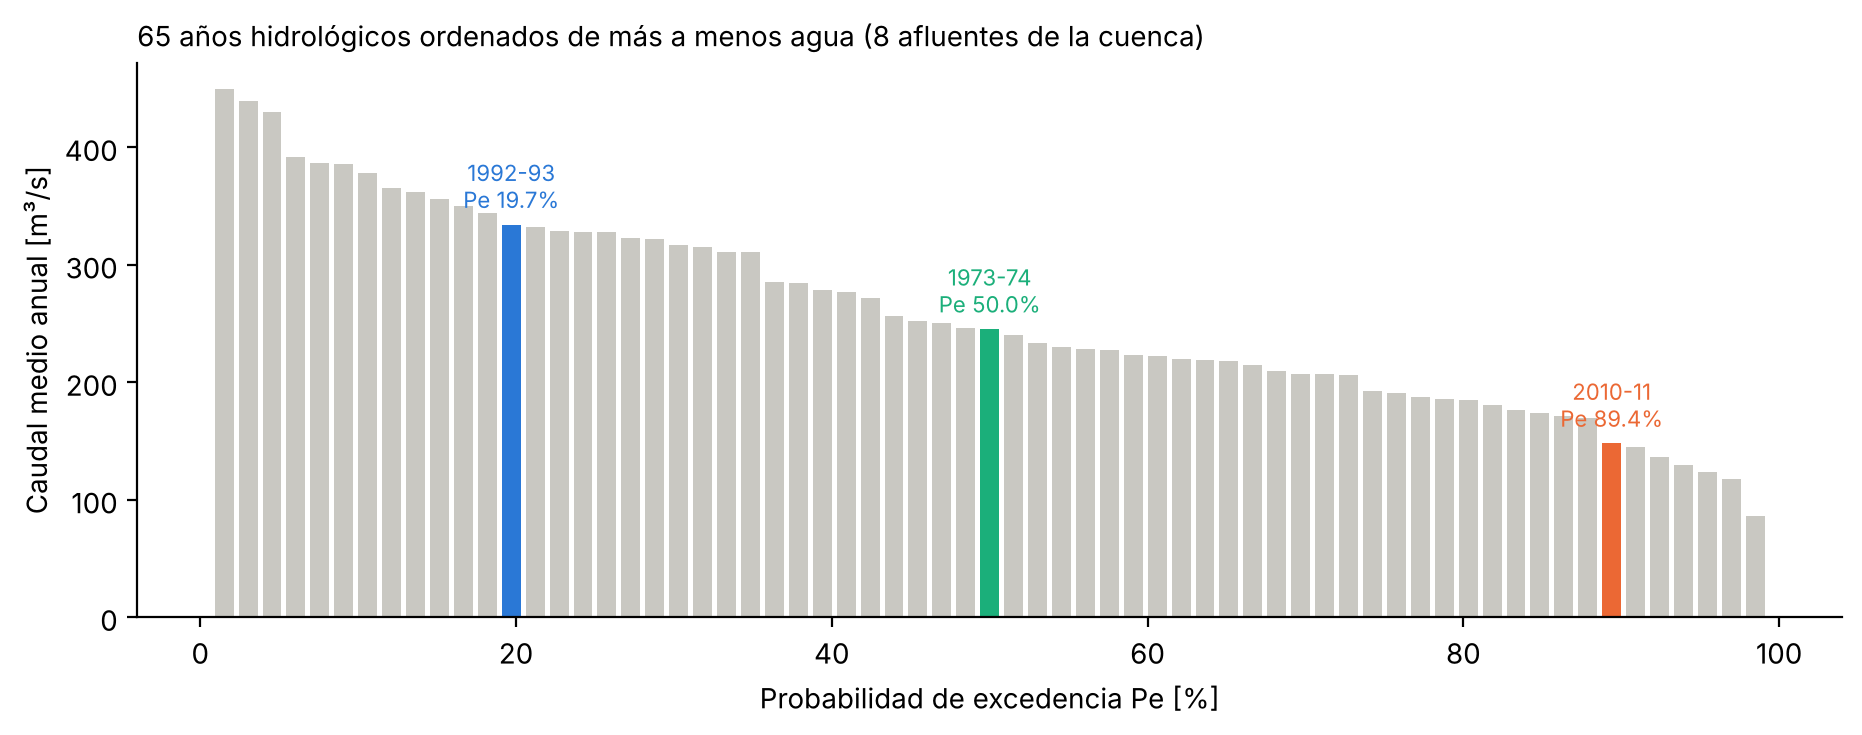

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.6))
col = {ESCENARIOS["Húmedo"]: "#2a78d6", ESCENARIOS["Medio"]: "#1baf7a", ESCENARIOS["Seco"]: "#eb6834"}
ax.bar(vol["Pe_%"], vol.caudal_medio_m3s, width=1.2,
       color=[col.get(a, "#c9c8c2") for a in vol.anio])
for a, c in col.items():
    f = vol[vol.anio == a].iloc[0]
    ax.annotate(f"{etiqueta(a)}\nPe {f['Pe_%']:.1f}%", (f["Pe_%"], f.caudal_medio_m3s),
                xytext=(0, 6), textcoords="offset points", ha="center", fontsize=8, color=c)
ax.set_xlabel("Probabilidad de excedencia Pe [%]")
ax.set_ylabel("Caudal medio anual [m³/s]")
ax.set_title("65 años hidrológicos ordenados de más a menos agua (8 afluentes de la cuenca)",
             loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**¿Por qué no usar los afluentes del pronóstico del CEN (`po12meses`)? (D2)** Hay tres razones:
- No trae la Laguna del Maule, que habría que estimar.
- Su fila de B_Maule incluye La Mina e Isla, que hay que restar.
- Sus 5 hidrologías están clasificadas según la energía de **todo el sistema eléctrico**, no según el Maule.

La tabla lo muestra. Cada número es la suma del caudal medio que entra por los afluentes de la cuenca (La Invernada, La Mina, Isla, B_Maule, Melado, CMNTronco y Colbún). Se deja fuera **solo el afluente de la Laguna del Maule**, porque el pronóstico del CEN no lo trae; así se comparan las dos fuentes con los mismos 7 afluentes. En el pronóstico, la hidrología **HUMEDA trae menos agua al Maule que la SECA**. Con los años históricos elegidos por Pe, en cambio, el orden es el correcto. El pronóstico del CEN queda como referencia para validar, no como entrada del modelo.

In [12]:
# Comprobación (D2): ¿cuánta agua trae al Maule cada hidrología del pronóstico CEN?
FILAS_CEN = {"CIPRESES": "a la lag. de la inv.", "B_LaMina": "de la cuenca intermedia la mina",
             "B_M_Isla": "de la cuenca intermedia isla", "Rio_Melado": "al embalse melado",
             "CMNTronco": "claro en san carlos + estero las garzas",
             "B_Maule": "c.i. maule en boca. pehu. - lag. inv. - lag. maule",
             "COLBUN": "c.i. muro colbun - armerillo"}
comp = {}
for hj in ["HUMEDA", "MEDIA", "SECA"]:
    f = {str(r[0]).strip(): np.array(r[1:1 + NT], float) for r in hoja(f"AFL. HID. {hj}")[:40]
         if r[0] and isinstance(r[1], (int, float))}
    a = {n: f[s] for n, s in FILAS_CEN.items()}
    a["B_Maule"] = a["B_Maule"] - a["B_LaMina"] - a["B_M_Isla"]     # esa fila incluye La Mina e Isla
    comp[f"CEN {hj}"] = sum(v.mean() for v in a.values())            # sin la Laguna (no viene)
for k, a in ESCENARIOS.items():
    comp[f"Histórico {k} {etiqueta(a)}"] = sum(AFL[a][s].mean() for s in SERIES_AFLUENTE if s != "LMAULE")
pd.Series(comp, name="Afluente total de la cuenca SIN la Laguna del Maule [m3/s]").round(1).to_frame()

,Afluente total de la cuenca SIN la Laguna del Maule [m3/s]
CEN HUMEDA,180.6
CEN MEDIA,255.1
CEN SECA,187.5
Histórico Húmedo 1992-93,320.0
Histórico Medio 1973-74,233.5
Histórico Seco 2010-11,138.1


## 6. Filtración, riego y régimen natural
**Filtración de La Invernada (D9).** Parte del agua de La Invernada se filtra por el suelo y reaparece aguas abajo, donde la turbina la central Ojos de Agua. Como no hay medición directa, se calibra con el pronóstico del CEN: la generación de Ojos de Agua (hoja `HID. MEDIA`, en GWh) dividida por su rendimiento (0,58 MW por m³/s) y por las horas da el caudal filtrado. Se usa el promedio del año, ≈ 11,8 m³/s, constante, como dice el Informe 1. Si en algún año muy seco La Invernada se vaciara, el modelo puede filtrar menos (no puede filtrar agua que no hay), y eso se informa.

**Régimen natural y gastos deficitarios (Convenio, Art. 2).** El *régimen natural* es el caudal del río sin la Laguna del Maule: la suma de los otros 7 afluentes. El *gasto deficitario* es lo que le falta al río para cubrir la demanda de riego:

$$D_t = \max\{0,\; d_t - \text{régimen natural}_t\}$$

Solo ese déficit se puede sacar de la Laguna para riego.

**Art. 8.** Rige en las semanas con déficit, o cuando el río natural va bajo 250 m³/s multiplicado por el % del mes.

La tabla muestra, por mes, la demanda, el régimen natural y el déficit de cada escenario. Solo el año seco tiene déficit relevante, entre diciembre y marzo.

In [13]:
def leer_filtracion(nombre_hoja="HID. MEDIA"):
    """Filtración constante de La Invernada hacia Ojos de Agua [m3/s]: caudal que explica la
    generación de Ojos de Agua en el pronóstico CEN = GWh*1000 / (0,58 MW/(m3/s) * horas)."""
    gwh = next(np.array([x or 0 for x in r[1:1 + NT]], float)
               for r in hoja(nombre_hoja) if r[0] and str(r[0]).strip() == "Ojos de Agua")
    return float(np.mean(gwh * 1000 / (RED.at["OJOS_DE_AGUA", "eta"] * H.sum(1))))


FILT = leer_filtracion()


def caudal_natural(afl):
    """Régimen natural del río sin la Laguna del Maule (Art. 2 y 8): suma de los demás afluentes."""
    return sum(v for s, v in afl.items() if s != LAGUNA)


def deficit_natural(afl, conv):
    """Gastos deficitarios (Art. 2): lo que le falta al río natural para cubrir la demanda de riego."""
    return np.maximum(0.0, conv["demanda"] - caudal_natural(afl))


def semanas_art8(afl, conv):
    """Semanas en que rige el Art. 8: hay déficit, o el río natural va bajo 250 m3/s x % del mes."""
    pct = np.array([PCT_RIEGO[m] for m in MES_ETAPA])
    return (deficit_natural(afl, conv) > 0) | (caudal_natural(afl) < CAUDAL_ART8 * pct)


print(f"Filtración de La Invernada: {FILT:.2f} m3/s (constante)")
tabla_riego = pd.DataFrame({"mes": [NOMBRE_MES[m] for m in MES_ETAPA], "demanda": CONV["demanda"]})
for k, a in ESCENARIOS.items():
    tabla_riego[f"natural {k}"] = caudal_natural(AFL[a])
    tabla_riego[f"déficit {k}"] = deficit_natural(AFL[a], CONV)
tabla_riego.groupby("mes", sort=False).mean().round(1)

Filtración de La Invernada: 11.84 m3/s (constante)


,demanda,natural Húmedo,déficit Húmedo,natural Medio,déficit Medio,natural Seco,déficit Seco
mes,,,,,,,
jul,0.0,265.1,0.0,285.8,0.0,122.9,0.0
ago,0.0,195.6,0.0,208.2,0.0,140.2,0.0
sep,32.0,278.2,0.0,186.8,0.0,161.3,0.0
oct,80.0,411.0,0.0,277.5,0.0,305.9,0.0
nov,145.6,623.4,0.0,430.5,0.0,268.1,0.0
dic,160.0,556.8,0.0,340.2,0.0,143.8,20.3
ene,160.0,312.1,0.0,224.8,0.0,88.3,71.7
feb,128.0,170.8,0.0,140.0,2.1,73.4,54.6
mar,88.0,118.0,0.0,108.5,0.0,66.0,22.0


## 7. El modelo de optimización
### Notación
| Símbolo | Significado | Unidad |
|---|---|---|
| $n \in N$, $e \in E \subset N$, $g \in G \subset N$ | nodos, embalses, centrales | |
| $t = 1..48$, $b = 1..5$ | semanas y bloques | |
| $h_{tb}$, $h_t = \sum_b h_{tb}$ | horas del bloque y de la semana | h |
| $\pi_{gtb}$ | costo marginal en la barra de la central $g$ | USD/MWh |
| $\eta_g$ | rendimiento de la central | MW/(m³/s) |
| $a_{nt}$ | afluente natural del nodo | m³/s |
| $\kappa = 0{,}0036$ | conversión de (m³/s)·h a hm³ | |
| $\bar q_n$, $\bar s_n$ | capacidad de turbinado/conducción y de vertimiento | m³/s |
| $V^0_e$, $V^{min}_e$, $V^{max}_e$ | volumen inicial, mínimo y máximo | hm³ |
| $d_t$, $D_t$ | demanda de riego y gasto deficitario | m³/s |
| $\varphi$ | filtración de La Invernada (11,8) | m³/s |

### Variables de decisión (esta celda)
| Variable | Significado | Unidad |
|---|---|---|
| $q_{ntb} \in [0, \bar q_n]$ | caudal turbinado o conducido por el nodo | m³/s |
| $s_{ntb} \in [0, \bar s_n]$ | caudal vertido por el nodo | m³/s |
| $V_{et}$ | volumen del embalse al final de la semana | hm³ |
| $\delta_{tb} \geq 0$ | riego no entregado (déficit) | m³/s |
| $f_t \in [0, \varphi]$ | filtración de La Invernada | m³/s |

Los límites de $V$ ya incluyen dos restricciones:
- **Reserva extraordinaria (Art. 6):** la Laguna del Maule nunca baja de 170 hm³.
- **Volumen final (D8):** en la semana 48 cada embalse termina con al menos lo que tenía al inicio, $V_{e,48} \geq V^0_e$. Sin esta condición, el modelo vaciaría los embalses al final del año, porque el agua que queda no le da ingreso dentro del horizonte. Eso infla artificialmente el caudal: con una condición blanda, el año seco daba 84 m³/s en B_Maule cuando el natural es 68.

In [14]:
def crear_variables(M):
    """q, s: caudal turbinado/conducido y vertido de cada nodo en cada bloque [m3/s].
    V: volumen de cada embalse al final de cada semana [hm3].
    deficit: riego no entregado [m3/s] (holgura penalizada para que el año seco no sea infactible).
    f: filtración de La Invernada [m3/s]; vale FILT salvo que la laguna esté vacía."""
    m = M["m"]
    T, B = range(NT), range(NB)
    M["q"] = m.addVars(NODOS, T, B, lb=0.0,
                       ub={(n, t, b): float(min(RED.at[n, "qmax"], 1e5)) for n in NODOS for t in T for b in B})
    M["s"] = m.addVars(NODOS, T, B, lb=0.0,
                       ub={(n, t, b): float(min(RED.at[n, "smax"], 1e5)) for n in NODOS for t in T for b in B})
    lbV = {(e, t): float(RED.at[e, "Vmin"]) for e in EMBALSES for t in T}
    for t in T:
        lbV[LAGUNA, t] = max(lbV[LAGUNA, t], V_INFERIOR)            # Art. 6: no se usa la reserva extraordinaria
    for e in EMBALSES:
        lbV[e, NT - 1] = max(lbV[e, NT - 1], float(RED.at[e, "V0"]))  # D8: volumen final >= inicial
    M["V"] = m.addVars(EMBALSES, T, lb=lbV,
                       ub={(e, t): float(RED.at[e, "Vmax"]) for e in EMBALSES for t in T})
    M["deficit"] = m.addVars(T, B, lb=0.0)
    M["f"] = m.addVars(T, lb=0.0, ub=FILT)

### Restricciones físicas
**R1. Balance en nodos de pasada** (cada bloque): lo que sale es igual a lo que entra.

$$q_{ntb} + s_{ntb} = a_{nt} + \sum_{k:\,\text{abajo}_q(k)=n} q_{ktb} + \sum_{k:\,\text{abajo}_s(k)=n} s_{ktb}$$

**R2. Balance en embalses** (cada semana): el volumen cambia según lo que entra y sale en los 5 bloques.

$$V_{et} = V_{e,t-1} + \kappa \sum_b h_{tb}\Big(\text{entra}_{etb} - q_{etb} - s_{etb}\Big) + \kappa\, h_t\, a_{et}, \qquad V_{e,0} = V^0_e$$

La filtración $f_t$ sale de La Invernada (se resta en su balance) y entra en `FILT_CIPRESES` (se suma), camino a Ojos de Agua.

**R3. Capacidades:** $0 \le q \le \bar q$, $0 \le s \le \bar s$, $V^{min} \le V \le V^{max}$ (definidas en los límites de las variables).

**R4. Mínimo técnico de Machicura:** es la única central con potencia mínima (18,6 MW ≈ 56 m³/s). Con una binaria $u_{tb}$ (1 = opera):

$$q^{min}\, u_{tb} \;\le\; q_{\text{Machicura},tb} \;\le\; \bar q\, u_{tb}$$

Si no opera, el agua pasa vertida.

In [15]:
def agregar_balances(M):
    """Conservación del agua en cada nodo.
    Nodo de pasada (cada bloque):  q + s = afluente + lo que llega de aguas arriba.
    Embalse (cada semana):         V[t] = V[t-1] + KAPPA * sum_b horas * (entra - sale) + KAPPA * horas * afluente."""
    m, q, s, V, afl, f = M["m"], M["q"], M["s"], M["V"], M["afl_nodo"], M["f"]
    for n in NODOS:
        for t in range(NT):
            llega = {b: gp.quicksum(q[k, t, b] for k in LLEGA_Q[n]) + gp.quicksum(s[k, t, b] for k in LLEGA_S[n])
                     for b in range(NB)}
            if n == INVERNADA:              # la filtración sale de La Invernada ...
                llega = {b: llega[b] - f[t] for b in range(NB)}
            if n == "FILT_CIPRESES":        # ... y reaparece aguas abajo, camino a Ojos de Agua
                llega = {b: llega[b] + f[t] for b in range(NB)}
            if RED.at[n, "embalse"]:
                anterior = V[n, t - 1] if t > 0 else float(RED.at[n, "V0"])
                neto = gp.quicksum(KAPPA * float(H[t, b]) * (llega[b] - q[n, t, b] - s[n, t, b]) for b in range(NB))
                m.addConstr(V[n, t] == anterior + neto + float(KAPPA * H[t].sum() * afl[n][t]))
            else:
                for b in range(NB):
                    m.addConstr(q[n, t, b] + s[n, t, b] == llega[b] + float(afl[n][t]))


def agregar_minimo_machicura(M):
    """Machicura tiene potencia mínima: si opera (on = 1), turbina entre qmin y qmax."""
    m, q = M["m"], M["q"]
    qmin, qmax = float(RED.at[MACHICURA, "qmin"]), float(RED.at[MACHICURA, "qmax"])
    M["on"] = on = m.addVars(range(NT), range(NB), vtype=GRB.BINARY)
    for t in range(NT):
        for b in range(NB):
            m.addConstr(q[MACHICURA, t, b] >= qmin * on[t, b])
            m.addConstr(q[MACHICURA, t, b] <= qmax * on[t, b])

**R5. Riego obligatorio (D7):** en cada bloque, lo que entra a los 4 canales más el déficit debe cubrir la demanda del mes.

$$\sum_{n \in \text{canales}} (\text{agua al canal})_{ntb} + \delta_{tb} \;\geq\; d_t$$

El déficit $\delta$ tiene una penalización muy alta en el objetivo, así que el modelo cumple el riego siempre que sea físicamente posible. La holgura existe para que un año extremadamente seco no deje el modelo *infactible*: en vez de no entregar respuesta, informa cuánto riego faltó. En los 65 años históricos el déficit resultó 0.

In [16]:
def riego_canales(M, t, b):
    """Agua que entra a los 4 canales de riego en el bloque (q, y s si el vertimiento también es canal)."""
    q, s = M["q"], M["s"]
    return gp.quicksum(q[n, t, b] + (s[n, t, b] if RED.at[n, "abajo_s"] is None else 0) for n in CANALES)


def agregar_riego(M):
    """Riego obligatorio: lo que entra a los canales + déficit >= demanda del mes, en cada bloque."""
    m, dem = M["m"], M["conv"]["demanda"]
    for t in range(NT):
        for b in range(NB):
            m.addConstr(riego_canales(M, t, b) + M["deficit"][t, b] >= float(dem[t]))

### Restricciones del Convenio de 1947 (D10)
El Convenio regula dos lagunas. En la **Laguna del Maule** separa el agua para riego de la cuota para generación de Endesa (hoy Enel) y pone límites según cuánta agua quede. **La Invernada** no puede acumular agua en los períodos deficitarios.

**Porciones de la Laguna** (con gasto 160 m³/s): inferior 0–170 hm³ (reserva extraordinaria, no se usa), intermedia 170–510 hm³ (reserva ordinaria, uso restringido) y superior sobre 510 hm³ (uso normal). La Laguna parte en 664,7 hm³, en la porción superior.

| Regla | Artículo | Restricción |
|---|---|---|
| C1 | Art. 2 y 4 | Todo lo que sale de la Laguna es riego $r_{tb}$ o generación $g_{tb}$: $q_{LM,tb} + s_{LM,tb} = r_{tb} + g_{tb}$. El riego no puede superar el gasto deficitario: $r_{tb} \le D_t$ |
| C2 | Art. 4 | Cuota especial para generación: $\sum_{t\in T_c,b} \kappa\, h_{tb}\, g_{tb} \le C_c$ hm³ para cada año calendario $c$ |
| C3 | Art. 4 | Promedio mensual de generación ≤ 25 m³/s |
| C4 | Art. 4 | Generación ≤ 30 m³/s en todo bloque (tope diario) |
| C5 | Art. 1 y 2 | Binaria $y_t = 1$ si la Laguna está en la porción superior al inicio de la semana: $V_{LM,t-1} \ge 510 - M(1-y_t)$ y $V_{LM,t-1} \le 510 + M y_t$ |
| C6 | Art. 5b | Mientras se usa la reserva ordinaria ($y_t = 0$), la generación acumulada del año calendario ≤ 20 % × 340 + 20 % de lo que entró a la Laguna en esas semanas |
| C7 | Art. 3b | Mientras se usa la reserva ordinaria, el riego acumulado de la temporada (sep–may) ≤ 80 % × 340 + 80 % de lo que entró |
| C8 | Art. 3c | Riego desde la Laguna en la temporada ≤ 800 hm³ |
| C9 | Art. 8 | Mientras rige el Art. 8, La Invernada no puede terminar la semana con más agua que la que tenía al empezar ese período: $V_{INV,t} \le V_{INV,\,\text{inicio}-1}$ |

**Cómo se linealizan C6 y C7.** Las variables auxiliares $g^{RO}_t$ y $r^{RO}_t$ (hm³ usados en la reserva ordinaria) cumplen $g^{RO}_t \ge \kappa \sum_b h_{tb} g_{tb} - M_t\, y_t$. Cuando $y_t = 0$ valen al menos lo extraído en la semana; cuando $y_t = 1$ pueden ser 0. El término $(1 - y_k)$ hace que solo sume la entrada de agua de las semanas en reserva ordinaria. $M$ es el volumen máximo de la Laguna, un número suficientemente grande para que la restricción quede "apagada" cuando no aplica.

**Supuestos de esta sección:**
- **Cuota por año calendario.** El Convenio da 250 hm³ por año calendario. Como el horizonte va de julio de 2026 a junio de 2027, C2 se impone por separado para 2026 y 2027. Para 2026 se usa un parámetro de cuota disponible igual a 250 hm³ menos lo utilizado entre enero y junio de 2026; mientras ese uso previo no se observe, el caso base supone un uso a prorrata de 125 hm³ (medio año), por lo que quedan 125 hm³ para julio-diciembre de 2026 y 250 hm³ para enero-junio de 2027; este supuesto debe sensibilizarse. No se modela todavía la acumulación interanual de cuota hasta 350 hm³.
- **No se modelan** la cuota suplementaria de invierno (Art. 5d, requiere autorización y un pronóstico de nieve) ni las "economías" de agua de los Arts. 8 y 9.
- **Vertimientos preventivos permitidos.** No se obliga a que un embalse esté lleno para verter, porque el Informe 1 trata el vertimiento preventivo como una decisión más. El costo de desempate hace que el modelo no vierta sin razón.

In [17]:
def agregar_convenio(M):
    """Reglas del Convenio de 1947 sobre la Laguna del Maule y La Invernada."""
    m, q, s, V, conv = M["m"], M["q"], M["s"], M["V"], M["conv"]
    afl = M["afl"]
    T, B = range(NT), range(NB)
    dfn = deficit_natural(afl, conv)
    A = KAPPA * H.sum(1) * afl[LAGUNA]                    # hm3 que entran a la Laguna cada semana
    Vsup, Rord = conv["V_superior"], conv["reserva_ordinaria"]
    BIG = float(RED.at[LAGUNA, "Vmax"])

    # C1 (Art. 2 y 4): todo lo que sale de la Laguna es riego (r) o generación (g)
    r = m.addVars(T, B, lb=0.0, ub={(t, b): float(dfn[t]) for t in T for b in B})   # riego <= gastos deficitarios
    g = m.addVars(T, B, lb=0.0, ub=TOPE_DIARIO)                                       # C4: tope diario 30 m3/s
    for t in T:
        for b in B:
            m.addConstr(q[LAGUNA, t, b] + s[LAGUNA, t, b] == r[t, b] + g[t, b])

    # C2 (Art. 4): cuota especial para generación POR AÑO CALENDARIO.
    # El horizonte jul-2026 / jun-2027 cruza dos años calendario, por lo que
    # la cuota no se puede imponer sobre las 48 semanas completas.
    for anio in (2026, 2027):
        ts = [t for t in T if ANIO_CAL_ETAPA[t] == anio]
        m.addConstr(
            gp.quicksum(
                KAPPA * float(H[t, b]) * g[t, b]
                for t in ts for b in B
            ) <= CUOTA_DISPONIBLE[anio],
            name=f"C2_cuota_generacion_{anio}"
        )

    # C3 (Art. 4): promedio mensual de generación <= 25 m3/s
    for mes in sorted(set(MES_ETAPA)):
        ts = [t for t in T if MES_ETAPA[t] == mes]
        m.addConstr(gp.quicksum(float(H[t, b]) * g[t, b] for t in ts for b in B)
                    <= TOPE_MENSUAL * float(H[ts].sum()))

    # C5: y[t] = 1 si la Laguna está en la porción superior al inicio de la semana t
    y = m.addVars(T, vtype=GRB.BINARY)
    g_ro = m.addVars(T, lb=0.0)          # hm3 generados mientras se usa la reserva ordinaria
    r_ro = m.addVars(T, lb=0.0)          # hm3 regados mientras se usa la reserva ordinaria
    for t in T:
        if t == 0:
            sup0 = float(RED.at[LAGUNA, "V0"] >= Vsup)
            m.addConstr(y[0] == sup0)
        else:
            m.addConstr(V[LAGUNA, t - 1] >= Vsup - BIG * (1 - y[t]))
            m.addConstr(V[LAGUNA, t - 1] <= Vsup + BIG * y[t])
        sem_g = gp.quicksum(KAPPA * float(H[t, b]) * g[t, b] for b in B)
        sem_r = gp.quicksum(KAPPA * float(H[t, b]) * r[t, b] for b in B)
        m.addConstr(g_ro[t] >= sem_g - float(TOPE_DIARIO * KAPPA * H[t].sum()) * y[t])
        m.addConstr(r_ro[t] >= sem_r - float(max(dfn[t], 0) * KAPPA * H[t].sum()) * y[t])

    # C6 (Art. 5b): en la reserva ordinaria, generación acumulada del año calendario
    #               <= 20% de la reserva + 20% de lo que entró a la Laguna en ese tiempo
    for anio in (2026, 2027):
        ts = [t for t in T if ANIO_CAL_ETAPA[t] == anio]
        for j in range(len(ts)):
            u = ts[:j + 1]
            m.addConstr(gp.quicksum(g_ro[k] for k in u)
                        <= F_GEN * (Rord + gp.quicksum(float(A[k]) * (1 - y[k]) for k in u)))

    # C7 (Art. 3b): en la reserva ordinaria, riego acumulado de la temporada
    #               <= 80% de la reserva + 80% de lo que entró
    temporada = [t for t in T if PCT_RIEGO[MES_ETAPA[t]] > 0]
    for j in range(len(temporada)):
        u = temporada[:j + 1]
        m.addConstr(gp.quicksum(r_ro[k] for k in u)
                    <= F_RIEGO * (Rord + gp.quicksum(float(A[k]) * (1 - y[k]) for k in u)))

    # C8 (Art. 3c): riego desde la Laguna en la temporada <= 800 hm3
    m.addConstr(gp.quicksum(KAPPA * float(H[t, b]) * r[t, b] for t in temporada for b in B)
                <= MAX_RIEGO_TEMPORADA)

    # C9 (Art. 8): mientras rige, La Invernada no termina la semana con más agua
    #              que la que tenía al empezar el período deficitario
    art8 = semanas_art8(afl, conv)
    for t in T:
        if art8[t]:
            i = t
            while i > 0 and art8[i - 1]:
                i -= 1
            inicio = V[INVERNADA, i - 1] if i > 0 else float(RED.at[INVERNADA, "V0"])
            m.addConstr(V[INVERNADA, t] <= inicio)

    M.update(r=r, g=g, y=y, g_ro=g_ro, r_ro=r_ro, dfn=dfn, art8=art8)

### Función objetivo
Maximizar el ingreso por generación de todas las centrales, valorizado al costo marginal de su barra, menos las penalizaciones.

$$\max \;\; \underbrace{\sum_{g,t,b} \pi_{gtb}\, \eta_g\, h_{tb}\, q_{gtb}}_{\text{ingreso [USD]}} \;-\; P \sum_{t,b} h_{tb}\,\delta_{tb} \;-\; P \sum_t h_t\,(\varphi - f_t) \;-\; \varepsilon\,(\text{vertimientos} + \text{agua a canales})$$

$\pi \cdot \eta \cdot h$ es lo que gana la central por cada m³/s turbinado en el bloque: precio [USD/MWh] × MW por m³/s × horas. $P$ = 10.000 y $\varepsilon$ = 0,0001 (ver sección 2).

**¿Por qué centralizado? (D1)** En Chile las empresas no deciden por separado cuánto turbinar. El CEN despacha todo el sistema al mínimo costo y valora el agua de los embalses como costo de oportunidad (modelo PLP); cada central recibe CMg × energía. Un optimizador único que maximiza el ingreso de toda la cuenca reproduce esa lógica. El enfoque secuencial (cada central maximiza lo suyo, de arriba hacia abajo) da prioridad a las centrales de aguas arriba y no representa cómo se opera.

In [18]:
def definir_objetivo(M):
    """max  ingreso por generación  -  penalización del déficit de riego  -  desempate."""
    m, q, s = M["m"], M["q"], M["s"]
    pi = M["pi"]
    T, B = range(NT), range(NB)
    ingreso = gp.quicksum(float(pi[RED.at[n, "barra"]][t, b] * RED.at[n, "eta"] * H[t, b]) * q[n, t, b]
                          for n in CENTRALES for t in T for b in B)
    castigo = gp.quicksum(PEN_DEFICIT * float(H[t, b]) * M["deficit"][t, b] for t in T for b in B) \
        + gp.quicksum(PEN_DEFICIT * float(H[t].sum()) * (FILT - M["f"][t]) for t in T)
    desempate = gp.quicksum(DESEMPATE * float(H[t, b]) * s[n, t, b] for n in CENTRALES for t in T for b in B) \
        + gp.quicksum(DESEMPATE * float(H[t, b]) * (q[n, t, b] + s[n, t, b]) for n in CANALES for t in T for b in B)
    m.setObjective(ingreso - castigo - desempate, GRB.MAXIMIZE)
    M["ingreso_expr"] = ingreso

### Armar y resolver
- `afluentes_por_nodo` pone cada serie histórica en su nodo (0 en el resto).
- `construir_modelo` crea el modelo de Gurobi y agrega, en orden, variables, balances, mínimo de Machicura, riego, Convenio y objetivo. Recibe los afluentes del año y, opcionalmente, otros precios u otro gasto de riego (para las sensibilidades).
- `resolver` corre Gurobi, con un tope de 10 minutos y un gap de 0,01 %, y guarda la solución como matrices de 48 × 5 para analizarla con `numpy`.

El modelo resultante tiene ~16.700 variables (288 binarias) y ~8.200 restricciones. Con la licencia académica se resuelve en segundos.

In [19]:
def afluentes_por_nodo(afl):
    """Afluente natural de cada nodo [m3/s]: la serie histórica donde corresponde, 0 en el resto."""
    a = {n: np.zeros(NT) for n in NODOS}
    for s_, v in afl.items():
        a[s_] = a[s_] + v
    return a


def construir_modelo(afl, pi=None, conv=None):
    conv = conv or CONV
    pi = pi or PI
    m = gp.Model("Cuenca_Maule", env=ENV) if ENV is not None else gp.Model("Cuenca_Maule")
    M = dict(m=m, afl=afl, afl_nodo=afluentes_por_nodo(afl), pi=pi, conv=conv)
    crear_variables(M)
    agregar_balances(M)
    agregar_minimo_machicura(M)
    agregar_riego(M)
    agregar_convenio(M)
    definir_objetivo(M)
    return M


def resolver(M):
    """Resuelve el modelo y guarda la solución como matrices de numpy."""
    t0 = time.time()
    X = optimizar(M["m"])
    T, B = range(NT), range(NB)
    M["Q"] = {n: np.array([[X(M["q"][n, t, b]) for b in B] for t in T]) for n in NODOS}
    M["S"] = {n: np.array([[X(M["s"][n, t, b]) for b in B] for t in T]) for n in NODOS}
    M["Vx"] = {e: np.array([X(M["V"][e, t]) for t in T]) for e in EMBALSES}
    M["DEF"] = np.array([[X(M["deficit"][t, b]) for b in B] for t in T])
    M["F"] = np.array([X(M["f"][t]) for t in T])
    M["R"] = np.array([[X(M["r"][t, b]) for b in B] for t in T])
    M["G"] = np.array([[X(M["g"][t, b]) for b in B] for t in T])
    M["Y"] = np.array([round(X(M["y"][t])) for t in T])
    M["seg"] = time.time() - t0
    M["gap"] = X.gap
    return M


## 8. Verificación independiente
Esta función revisa la solución **sin usar Gurobi**: toma los caudales y volúmenes obtenidos y recalcula con `numpy` cada balance, capacidad, volumen final, mínimo técnico, el riego y las reglas del Convenio. Las porciones de la Laguna las calcula desde la trayectoria del volumen, sin mirar las binarias. Si algo no cuadra (con tolerancia de 0,001), lo informa. Es una prueba de que el modelo programado hace lo que dice la formulación.

In [20]:
def prom_semana(X):
    """Promedio de cada semana ponderado por las horas de cada bloque."""
    return (X * H).sum(1) / H.sum(1)


def verificar(M, tol=1e-3):
    """Revisa la solución sin usar el modelo: recalcula balances, capacidades y reglas."""
    Q, S, Vx, conv = M["Q"], M["S"], M["Vx"], M["conv"]
    a, err = dict(M["afl_nodo"]), []
    a[INVERNADA] = a[INVERNADA] - M["F"]
    a["FILT_CIPRESES"] = a["FILT_CIPRESES"] + M["F"]
    for n in NODOS:
        entra = sum((Q[k] for k in LLEGA_Q[n]), np.zeros((NT, NB))) + sum((S[k] for k in LLEGA_S[n]), np.zeros((NT, NB)))
        sale = Q[n] + S[n]
        if RED.at[n, "embalse"]:
            ant = np.r_[RED.at[n, "V0"], Vx[n][:-1]]
            esp = ant + KAPPA * ((H * (entra - sale)).sum(1) + H.sum(1) * a[n])
            if np.abs(esp - Vx[n]).max() > tol:
                err.append(f"balance {n}")
            if Vx[n][-1] < RED.at[n, "V0"] - tol:
                err.append(f"volumen final {n}")
            if Vx[n].min() < RED.at[n, "Vmin"] - tol or Vx[n].max() > RED.at[n, "Vmax"] + tol:
                err.append(f"límites de volumen {n}")
        elif np.abs(a[n][:, None] + entra - sale).max() > tol:
            err.append(f"balance {n}")
        if (Q[n] > RED.at[n, "qmax"] + tol).any() or (S[n] > RED.at[n, "smax"] + tol).any():
            err.append(f"capacidad {n}")
    qm = Q[MACHICURA]
    if ((qm > tol) & (qm < RED.at[MACHICURA, "qmin"] - tol)).any():
        err.append("mínimo técnico Machicura")
    riego = sum(Q[n] + (S[n] if RED.at[n, "abajo_s"] is None else 0) for n in CANALES)
    if (riego + M["DEF"] < conv["demanda"][:, None] - tol).any():
        err.append("riego")
    # Convenio, recalculado desde la trayectoria de la Laguna
    if np.abs(Q[LAGUNA] + S[LAGUNA] - M["R"] - M["G"]).max() > tol:
        err.append("C1 salida de la Laguna")
    if (M["R"] > M["dfn"][:, None] + tol).any():
        err.append("C1 riego sobre el déficit")
    gen_hm3 = KAPPA * (H * M["G"]).sum(1)
    rie_hm3 = KAPPA * (H * M["R"]).sum(1)
    # C2: verificar la cuota por separado en cada año calendario
    for anio in (2026, 2027):
        ts_c2 = [t for t in range(NT) if ANIO_CAL_ETAPA[t] == anio]
        if gen_hm3[ts_c2].sum() > CUOTA_DISPONIBLE[anio] + tol:
            err.append(f"C2 cuota {anio}")
    for mes in set(MES_ETAPA):
        ts = [t for t in range(NT) if MES_ETAPA[t] == mes]
        if (H[ts] * M["G"][ts]).sum() / H[ts].sum() > TOPE_MENSUAL + tol:
            err.append(f"C3 tope mensual {NOMBRE_MES[mes]}")
    if M["G"].max() > TOPE_DIARIO + tol:
        err.append("C4 tope diario")
    if Vx[LAGUNA].min() < V_INFERIOR - tol:
        err.append("reserva extraordinaria")
    Vini = np.r_[RED.at[LAGUNA, "V0"], Vx[LAGUNA][:-1]]
    borde = np.abs(Vini - conv["V_superior"]) <= tol          # justo en el límite: vale lo que diga y
    ro = (Vini < conv["V_superior"] - tol) | (borde & (M["Y"] == 0))
    if ((Vini < conv["V_superior"] - tol) & (M["Y"] == 1)).any() or ((Vini > conv["V_superior"] + tol) & (M["Y"] == 0)).any():
        err.append("C5 porción de la Laguna")
    A = KAPPA * H.sum(1) * M["afl"][LAGUNA]
    for anio, ts in ((2026, range(0, 24)), (2027, range(24, NT))):
        ts = np.array(list(ts))
        if (np.cumsum(gen_hm3[ts] * ro[ts]) > F_GEN * (conv["reserva_ordinaria"] + np.cumsum(A[ts] * ro[ts])) + tol).any():
            err.append(f"C6 Art. 5b {anio}")
    ts = np.array([t for t in range(NT) if PCT_RIEGO[MES_ETAPA[t]] > 0])
    if (np.cumsum(rie_hm3[ts] * ro[ts]) > F_RIEGO * (conv["reserva_ordinaria"] + np.cumsum(A[ts] * ro[ts])) + tol).any():
        err.append("C7 Art. 3b")
    if rie_hm3[ts].sum() > MAX_RIEGO_TEMPORADA + tol:
        err.append("C8 Art. 3c")
    Vin = np.r_[RED.at[INVERNADA, "V0"], Vx[INVERNADA]]
    art8 = M["art8"]
    for t in range(NT):
        if art8[t]:
            i = t
            while i > 0 and art8[i - 1]:
                i -= 1
            if Vin[t + 1] > Vin[i] + tol:
                err.append(f"C9 Art. 8 semana {t + 1}")
    return err

### Indicadores
- **Caudal en B_Maule** = $q + s$ del nodo B_Maule: todo lo que llega al punto de la nueva central (después se divide entre la bocatoma de Pehuenche y el río).
- **Caudal natural en B_Maule** = suma de los 5 afluentes aguas arriba (Laguna del Maule, Invernada, La Mina, Isla y la cuenca propia de B_Maule). Es lo que llegaría si nadie regulara.
- **Q50 y Q90:** caudal igualado o superado el 50 % y el 90 % del tiempo (cada bloque pesa sus horas). El Q90 indica con cuánto caudal se puede contar casi siempre: es clave para dimensionar la nueva central.
- **CMg obtenido** = ingreso / energía: muestra si el modelo logra vender en las horas caras.

In [21]:
def caudal_punto(M):
    """Caudal que llega al punto de interés (B_Maule) en cada bloque [m3/s]."""
    return M["Q"][PUNTO] + M["S"][PUNTO]


def excedido(X, pct):
    """Caudal igualado o superado el pct% del tiempo (cada bloque pesa sus horas)."""
    v, w = X.flatten(), H.flatten()
    o = np.argsort(-v)
    return float(v[o][np.searchsorted(np.cumsum(w[o]) / w.sum(), pct / 100)])


def resumen(M, nombre, anio):
    Q, S, pi = M["Q"], M["S"], M["pi"]
    Qp = caudal_punto(M)
    nat = sum(M["afl"][s] for s in AGUAS_ARRIBA_PUNTO)
    energia = sum((RED.at[n, "eta"] * Q[n] * H).sum() for n in CENTRALES) / 1e3
    ingreso = sum((RED.at[n, "eta"] * Q[n] * H * pi[RED.at[n, "barra"]]).sum() for n in CENTRALES) / 1e6
    riego = sum(Q[n] + (S[n] if RED.at[n, "abajo_s"] is None else 0) for n in CANALES)
    fila = {
        "escenario": nombre, "año hidrológico": etiqueta(anio),
        "Pe [%]": float(vol.loc[vol.anio == anio, "Pe_%"].iloc[0]),
        "Q medio en B_Maule [m3/s]": (Qp * H).sum() / H.sum(),
        "Q natural en B_Maule [m3/s]": (nat * H.sum(1)).sum() / H.sum(),
        "Q mínimo semanal [m3/s]": prom_semana(Qp).min(),
        "Q50 [m3/s]": excedido(Qp, 50), "Q90 [m3/s]": excedido(Qp, 90),
        "Energía [GWh]": energia, "Ingreso [MUSD]": ingreso,
        "CMg obtenido [USD/MWh]": ingreso * 1e6 / (energia * 1e3),
        "Demanda de riego [hm3]": KAPPA * (M["conv"]["demanda"][:, None] * H).sum(),
        "Riego entregado [hm3]": KAPPA * (np.minimum(riego, M["conv"]["demanda"][:, None]) * H).sum(),
        "Déficit de riego [hm3]": KAPPA * (M["DEF"] * H).sum(),
        "Generación desde la Laguna [hm3]": KAPPA * (M["G"] * H).sum(),
        "Riego desde la Laguna [hm3]": KAPPA * (M["R"] * H).sum(),
        "Semanas en reserva ordinaria": int((M["Y"] == 0).sum()),
        "Filtración no cubierta [hm3]": KAPPA * ((FILT - M["F"]) * H.sum(1)).sum(),
        "Tiempo [s]": M["seg"], "Gap MIP": M["gap"],
    }
    for e in EMBALSES:
        fila[f"V final {e} [hm3]"] = M["Vx"][e][-1]
    return fila

## 9. Resultados de los 3 escenarios
Se arma y resuelve un modelo por escenario, y cada solución pasa por la verificación.

**Qué deberían ver:**

| | Húmedo 1992-93 | Medio 1973-74 | Seco 2010-11 |
|---|---|---|---|
| Caudal medio en B_Maule | ≈ 136 m³/s | ≈ 98 m³/s | ≈ 68 m³/s |
| Caudal natural | ≈ 139 m³/s | ≈ 98 m³/s | ≈ 68 m³/s |
| Ingreso | ≈ 421 MUSD | ≈ 391 MUSD | ≈ 280 MUSD |
| Déficit de riego | 0 | 0 | 0 |

**Cómo leerlo:**
- El ingreso queda ordenado húmedo > medio > seco, como corresponde con los mismos precios.
- El caudal medio anual en B_Maule queda igual o un poco bajo el natural. Por la condición de volumen final, la Laguna y La Invernada no pueden entregar más agua de la que reciben en el año; en los años con más agua la Laguna guarda parte y termina sobre su volumen inicial.
- Los embalses no cambian cuánta agua pasa en el año, sino **cuándo** pasa: la Laguna guarda en primavera y suelta en verano. Eso se ve en el gráfico.

In [22]:
RES = {}
for nombre, anio in ESCENARIOS.items():
    M = resolver(construir_modelo(AFL[anio]))
    errores = verificar(M)
    RES[nombre] = M
    estado = "verificación OK" if not errores else f"REVISAR: {errores[:5]}"
    print(f"{nombre:7s} {etiqueta(anio)}: Q medio en B_Maule = {(caudal_punto(M) * H).sum() / H.sum():6.1f} m3/s"
          f" | {M['seg']:5.1f} s | {estado}")

TABLA = pd.DataFrame([resumen(RES[k], k, a) for k, a in ESCENARIOS.items()]).set_index("escenario").T
TABLA.round(2)

Restricted license - for non-production use only - expires 2027-11-29


Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


Húmedo  1992-93: Q medio en B_Maule =  135.9 m3/s |   0.4 s | verificación OK


Medio   1973-74: Q medio en B_Maule =   98.1 m3/s |   1.3 s | verificación OK


Seco    2010-11: Q medio en B_Maule =   68.2 m3/s |   0.6 s | verificación OK


escenario,Húmedo,Medio,Seco
año hidrológico,1992-93,1973-74,2010-11
Pe [%],19.69697,50.0,89.393939
Q medio en B_Maule [m3/s],135.91588,98.051186,68.196968
Q natural en B_Maule [m3/s],138.774093,98.051186,68.196968
Q mínimo semanal [m3/s],70.92456,68.809152,42.33868
Q50 [m3/s],118.717329,100.170367,74.010516
Q90 [m3/s],79.022495,52.198478,28.537184
Energía [GWh],11632.286571,9865.732049,6598.352582
Ingreso [MUSD],421.076997,391.333417,279.973578
CMg obtenido [USD/MWh],36.198988,39.665928,42.43083


### Comparación con el caso base: operación secuencial con objetivo semanal
Los lineamientos piden comparar los KPIs con una **línea base**: una forma intuitiva, no analítica, de operar. Se usa una política de **operación secuencial con objetivo semanal**: en cada semana se maximiza únicamente el ingreso de esa semana, se fijan las decisiones adoptadas y se avanza a la siguiente, hasta la semana 48.

**Por qué este caso base y no un miope puro.** Para que la comparación sea justa, el caso base tiene **las mismas condiciones de borde y obligaciones que el modelo**: la misma física, las reglas del Convenio, la condición terminal $V_{n,48} \ge V_{n,0}$ y el riego **sin déficit** en las 48 semanas (el modelo principal obtiene déficit cero en los tres escenarios). Las restricciones de las semanas futuras siguen activas, así que la política secuencial debe conservar la factibilidad del resto del año: no es completamente miope, ve las restricciones futuras, pero **no valoriza el ingreso de las semanas siguientes**. Así, la diferencia con el modelo mide solo el efecto de valorizar en conjunto las 48 semanas.

El caso base anterior (miope puro, sin condición terminal y con el riego como holgura penalizada solo en la semana en curso) no era comparable: en el año seco "ganaba" caudal medio bajando la Laguna de 665 a 243 hm³, y al agregarle solo la condición terminal dejaba ~295 hm³ de riego sin cubrir, porque cada semana ignoraba el castigo del déficit de las semanas futuras. Ambas variantes se conservan como sensibilidad en la sección 11d.

**Qué muestra la comparación** (corrida de este notebook, ver tabla):
- **Caudal medio:** es el mismo en ambos enfoques (135,9; 98,1 y 68,2 m³/s en húmedo, medio y seco) y ambos terminan con la Laguna en el mismo volumen. Planificar no crea agua.
- **Distribución temporal:** el modelo anual tiene mayor $Q_{90}$ y mayor mínimo semanal en los tres escenarios. La diferencia más grande está en el año medio, donde el mínimo semanal sube de ~31 a 68,8 m³/s. Eso es lo que importa para dimensionar la nueva central.
- **Ingreso:** el modelo gana entre ~16 y ~47 MUSD más al año, porque mueve el agua a las semanas y bloques caros.

**Interpretación:** la planificación anual cambia **cuándo** se libera el agua y, en estas corridas, evita episodios de caudal muy bajo. El modelo no maximiza directamente el $Q_{90}$ ni el mínimo semanal, así que estas mejoras son resultados observados y no objetivos impuestos. Por eso el caudal medio siempre se reporta junto al **Q90**, el **mínimo semanal**, el **déficit de riego** y el **volumen final** de los embalses.

*Nota:* en la política secuencial cada semana puede tener varias soluciones con el mismo ingreso, así que otro solver (Gurobi o HiGHS) puede dar cifras de ingreso algo distintas. El caudal medio y los volúmenes finales no cambian; el modelo optimizado no tiene ese problema.


In [23]:
def caso_base_secuencial(afl, pi=None, conv=None, condicion_terminal=True, riego_estricto=True):
    """Caso base: operación secuencial con objetivo semanal.

    En la semana t solo se valoriza el ingreso de esa semana; luego se fijan sus decisiones y se
    avanza a la t+1. Las restricciones de las semanas futuras siguen activas.

    condicion_terminal=True  mantiene V_final >= V_inicial (igual que el modelo).
    riego_estricto=True      exige déficit de riego cero en las 48 semanas (igual al resultado del
                             modelo). Con False el déficit es una holgura penalizada solo en la semana
                             en curso, como en el miope puro.
    Con (False, False) se obtiene el miope puro de la entrega anterior (sensibilidad de la sección 11d).
    """
    M = construir_modelo(afl, pi, conv)
    m, q, s, pi_ = M["m"], M["q"], M["s"], M["pi"]
    if not condicion_terminal:                             # sin condición de volumen final
        for e in EMBALSES:
            M["V"][e, NT - 1].LB = V_INFERIOR if e == LAGUNA else float(RED.at[e, "Vmin"])
    if riego_estricto:                                     # riego sin déficit en todo el horizonte
        for t in range(NT):
            for b in range(NB):
                M["deficit"][t, b].UB = 0.0
    t0 = time.time()
    for t in range(NT):
        B = range(NB)
        ingreso_t = gp.quicksum(float(pi_[RED.at[n, "barra"]][t, b] * RED.at[n, "eta"] * H[t, b]) * q[n, t, b]
                                for n in CENTRALES for b in B)
        castigo_t = PEN_DEFICIT * float(H[t].sum()) * (FILT - M["f"][t])
        if not riego_estricto:
            castigo_t += gp.quicksum(PEN_DEFICIT * float(H[t, b]) * M["deficit"][t, b] for b in B)
        desempate_t = gp.quicksum(DESEMPATE * float(H[t, b]) * s[n, t, b] for n in CENTRALES for b in B)
        m.setObjective(ingreso_t - castigo_t - desempate_t, GRB.MAXIMIZE)
        try:
            X = optimizar(m)
        except RuntimeError as err:
            raise RuntimeError(f"Caso base secuencial: semana {t + 1} sin solución ({err})")
        continuas = [q[n, t, b] for n in NODOS for b in B] + [s[n, t, b] for n in NODOS for b in B] \
            + [M["V"][e, t] for e in EMBALSES] + [M["deficit"][t, b] for b in B] + [M["f"][t]] \
            + [M["r"][t, b] for b in B] + [M["g"][t, b] for b in B] + [M["g_ro"][t], M["r_ro"][t]]
        binarias = [M["y"][t]] + [M["on"][t, b] for b in B]
        valores = [X(v) for v in continuas] + [round(X(v)) for v in binarias]
        for v, x_ in zip(continuas + binarias, valores):     # se fijan las decisiones de la semana t
            v.LB, v.UB = x_, x_
    M = resolver(M)
    M["seg"] = time.time() - t0
    return M


def caso_base_miope(afl, pi=None, conv=None):
    """Miope puro (caso base de la entrega anterior): sin condición terminal y riego penalizado semana a semana."""
    return caso_base_secuencial(afl, pi, conv, condicion_terminal=False, riego_estricto=False)


BASE = {}
for nombre, anio in ESCENARIOS.items():
    BASE[nombre] = caso_base_secuencial(AFL[anio])
    errores = verificar(BASE[nombre])                      # mismas condiciones de borde: se verifica todo
    print(f"{nombre:7s}: caso base secuencial resuelto en {BASE[nombre]['seg']:.0f} s | "
          + ("verificación OK" if not errores else f"REVISAR: {errores[:5]}"))

KPI = ["Q medio en B_Maule [m3/s]", "Q50 [m3/s]", "Q90 [m3/s]", "Q mínimo semanal [m3/s]",
       "Energía [GWh]", "Ingreso [MUSD]", "CMg obtenido [USD/MWh]", "Déficit de riego [hm3]",
       "V final LMAULE [hm3]", "V final COLBUN [hm3]"]
filas = {}
for k, a in ESCENARIOS.items():
    rm, rb = resumen(RES[k], k, a), resumen(BASE[k], k, a)
    for kpi in KPI:
        filas[(k, kpi)] = {"Caso base (secuencial)": rb[kpi], "Modelo (planificación anual)": rm[kpi],
                           "Diferencia": rm[kpi] - rb[kpi]}
COMPARACION = pd.DataFrame(filas).T
COMPARACION.round(1)


Húmedo : caso base secuencial resuelto en 9 s | verificación OK


Medio  : caso base secuencial resuelto en 9 s | verificación OK


Seco   : caso base secuencial resuelto en 10 s | verificación OK


Caso base (secuencial)  Modelo (planificación anual)  Diferencia
Húmedo Q medio en B_Maule [m3/s]                   135.9                         135.9        -0.0
       Q50 [m3/s]                                  129.4                         118.7       -10.7
       Q90 [m3/s]                                   74.8                          79.0         4.2
       Q mínimo semanal [m3/s]                      58.6                          70.9        12.3
       Energía [GWh]                             11365.8                       11632.3       266.5
       Ingreso [MUSD]                              404.8                         421.1        16.3
       CMg obtenido [USD/MWh]                       35.6                          36.2         0.6
       Déficit de riego [hm3]                        0.0                           0.0         0.0
       V final LMAULE [hm3]                        754.9                         754.9         0.0
       V final COLBUN [hm3]                        708.0                         887.6       179.6
Medio  Q medio en B_Maule [m3/s]                    98.1                          98.1         0.0
       Q50 [m3/s]                                   95.9                         100.2         4.2
       Q90 [m3/s]                                   50.0                          52.2         2.2
       Q mínimo semanal [m3/s]                      31.0                          68.8        37.8
       Energía [GWh]                              9227.8                        9865.7       637.9
       Ingreso [MUSD]                              346.1                         391.3        45.3
       CMg obtenido [USD/MWh]                       37.5                          39.7         2.2
       Déficit de riego [hm3]                        0.0                           0.0         0.0
       V final LMAULE [hm3]                        664.7                         664.7         0.0
       V final COLBUN [hm3]                        565.2                         565.2         0.0
Seco   Q medio en B_Maule [m3/s]                    68.2                          68.2        -0.0
       Q50 [m3/s]                                   61.8                          74.0        12.2
       Q90 [m3/s]                                   26.7                          28.5         1.8
       Q mínimo semanal [m3/s]                      28.5                          42.3        13.8
       Energía [GWh]                              6163.3                        6598.4       435.1
       Ingreso [MUSD]                              232.7                         280.0        47.3
       CMg obtenido [USD/MWh]                       37.8                          42.4         4.7
       Déficit de riego [hm3]                        0.0                           0.0         0.0
       V final LMAULE [hm3]                        664.7                         664.7         0.0
       V final COLBUN [hm3]                        565.2                         565.2         0.0

**Izquierda:** caudal semanal en B_Maule según el modelo (línea gruesa) y el natural (punteada). **Derecha:** volumen de la Laguna del Maule; las líneas grises marcan dónde empieza la porción superior y la reserva extraordinaria. **Abajo:** curva de duración, que dice qué % del tiempo el caudal es igual o mayor a cada valor.

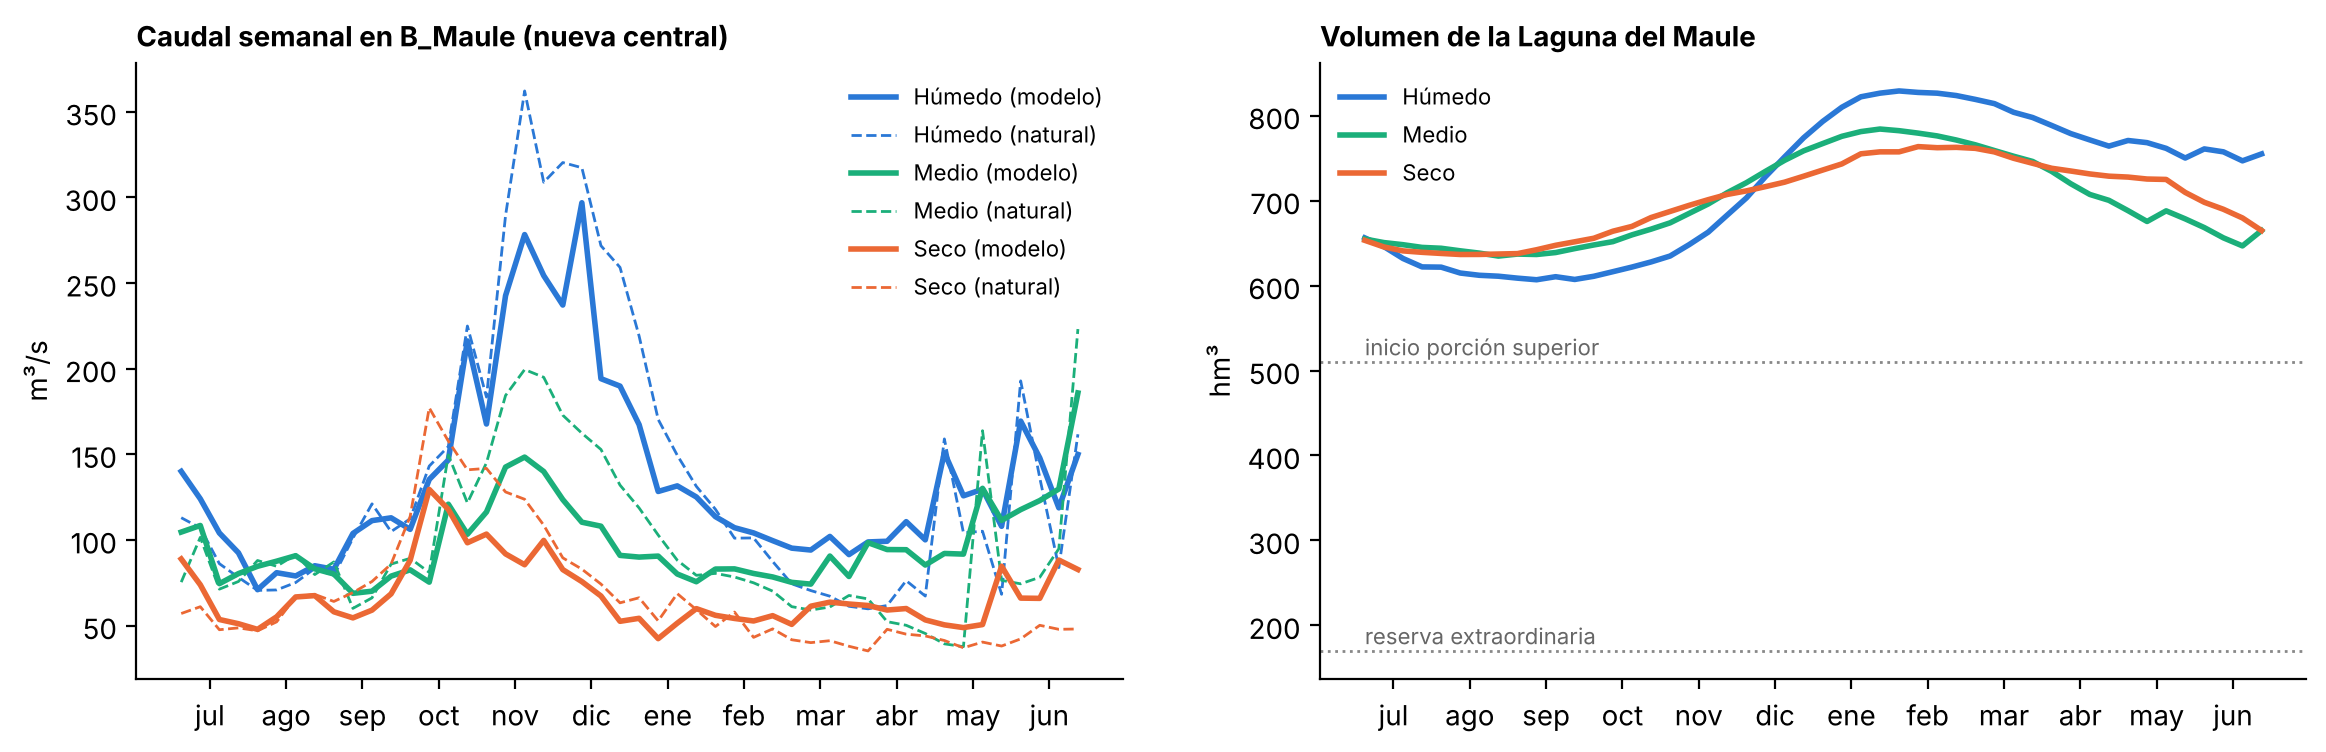

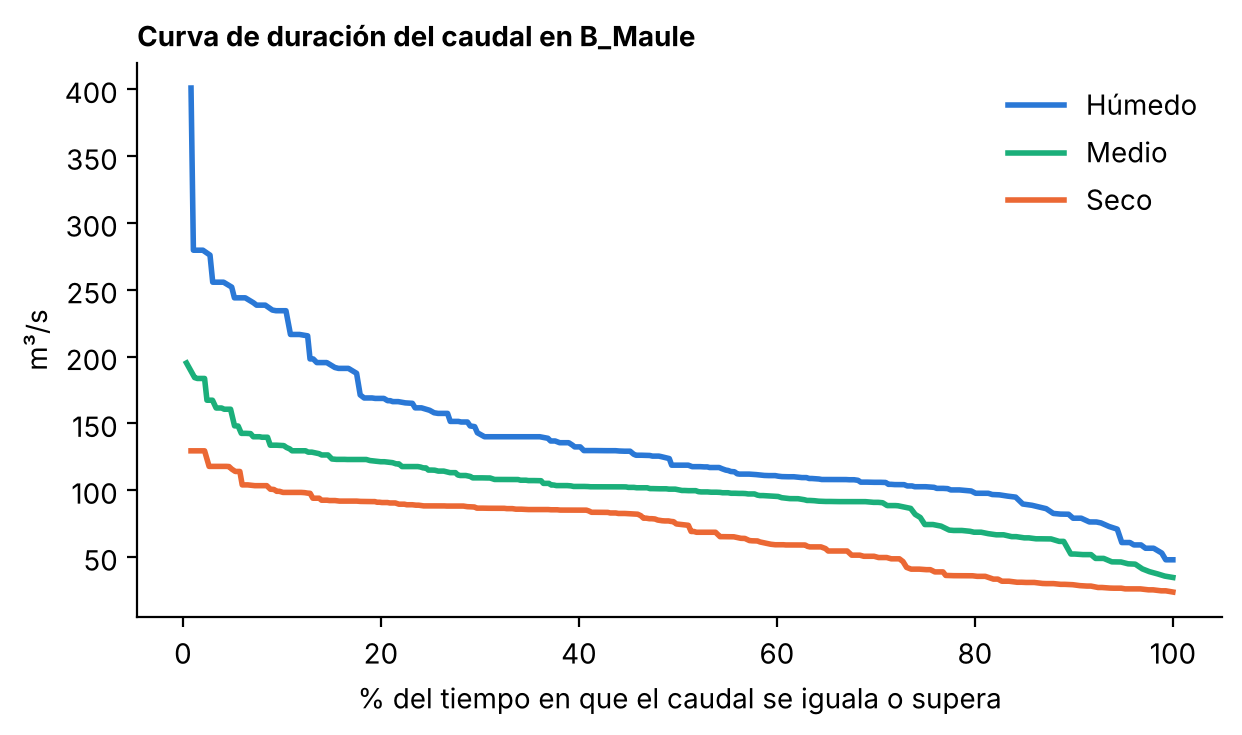

In [24]:
COLOR = {"Húmedo": "#2a78d6", "Medio": "#1baf7a", "Seco": "#eb6834"}
x = np.arange(1, NT + 1)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for k, M in RES.items():
    nat = sum(M["afl"][s] for s in AGUAS_ARRIBA_PUNTO)
    axs[0].plot(x, prom_semana(caudal_punto(M)), color=COLOR[k], lw=2, label=f"{k} (modelo)")
    axs[0].plot(x, nat, color=COLOR[k], lw=1, ls="--", label=f"{k} (natural)")
    axs[1].plot(x, M["Vx"][LAGUNA], color=COLOR[k], lw=2, label=k)
axs[1].axhline(CONV["V_superior"], color="#888", ls=":", lw=1)
axs[1].text(1, CONV["V_superior"] + 8, "inicio porción superior", fontsize=8, color="#666")
axs[1].axhline(V_INFERIOR, color="#888", ls=":", lw=1)
axs[1].text(1, V_INFERIOR + 8, "reserva extraordinaria", fontsize=8, color="#666")
for ax, tit, yl in [(axs[0], "Caudal semanal en B_Maule (nueva central)", "m³/s"),
                    (axs[1], "Volumen de la Laguna del Maule", "hm³")]:
    ax.set_xticks(np.arange(1, NT + 1, 4) + 1.5)
    ax.set_xticklabels([NOMBRE_MES[MES_ETAPA[t]] for t in range(0, NT, 4)])
    ax.set_title(tit, loc="left", fontsize=10, fontweight="bold")
    ax.set_ylabel(yl)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.6))
for k, M in RES.items():
    v, w = caudal_punto(M).flatten(), H.flatten()
    o = np.argsort(-v)
    ax.plot(100 * np.cumsum(w[o]) / w.sum(), v[o], color=COLOR[k], lw=2, label=k)
ax.set_xlabel("% del tiempo en que el caudal se iguala o supera")
ax.set_ylabel("m³/s")
ax.set_title("Curva de duración del caudal en B_Maule", loc="left", fontsize=10, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## 10. Archivo de resultados
Se crea y se descarga `resultados_modelo_final_maule.xlsx`, con estas hojas:

| Hoja | Contenido |
|---|---|
| `resumen` | La tabla de indicadores de los 3 escenarios |
| `caudal_B_Maule` | Caudal por semana y por bloque en el punto de interés, el natural, lo que va a Pehuenche y lo que sigue por el río |
| `generacion` | Por central: caudal turbinado y vertido, energía e ingreso |
| `volumenes` | Volumen semanal de los 4 embalses |
| `riego` | Demanda, agua entregada a cada canal y déficit |
| `laguna_convenio` | Laguna del Maule semana a semana: riego y generación, porción, si rige el Art. 8 y volumen de La Invernada |
| `afluentes` | Los afluentes y la filtración usados |
| `Pe_65_anios` | Los 65 años ordenados con su probabilidad de excedencia |
| `red` | La tabla de nodos y arcos |

In [25]:
def tablas_detalle(M, nombre, anio):
    Q, S, pi = M["Q"], M["S"], M["pi"]
    base = pd.DataFrame({"escenario": nombre, "año": etiqueta(anio), "semana": x,
                         "mes": [NOMBRE_MES[k] for k in MES_ETAPA], "horas": H.sum(1)})
    Qp = caudal_punto(M)
    cp = base.copy()
    for b in range(NB):
        cp[f"Q_bloque{b + 1}"] = Qp[:, b]
    cp["Q_semanal"] = prom_semana(Qp)
    cp["Q_natural"] = sum(M["afl"][s] for s in AGUAS_ARRIBA_PUNTO)
    cp["Q_a_Pehuenche"] = prom_semana(Q[PUNTO])
    cp["Q_sigue_por_el_rio"] = prom_semana(S[PUNTO])
    gen = []
    for n in CENTRALES:
        mw = RED.at[n, "eta"] * Q[n]
        gen.append({"escenario": nombre, "central": n, "barra": RED.at[n, "barra"],
                    "Q_turbinado_medio": (Q[n] * H).sum() / H.sum(),
                    "Q_vertido_medio": (S[n] * H).sum() / H.sum(),
                    "energia_GWh": (mw * H).sum() / 1e3,
                    "ingreso_MUSD": (mw * H * pi[RED.at[n, "barra"]]).sum() / 1e6})
    vols = base.copy()
    for e in EMBALSES:
        vols[f"V_{e}"] = M["Vx"][e]
    rie = base.copy()
    rie["demanda"] = M["conv"]["demanda"]
    for n in CANALES:
        rie[n] = prom_semana(Q[n] + (S[n] if RED.at[n, "abajo_s"] is None else 0))
    rie["deficit"] = prom_semana(M["DEF"])
    lag = base.copy()
    lag["V_Laguna"] = M["Vx"][LAGUNA]
    lag["afluente_Laguna"] = M["afl"][LAGUNA]
    lag["deficit_natural"] = M["dfn"]
    lag["riego_desde_Laguna"] = prom_semana(M["R"])
    lag["generacion_desde_Laguna"] = prom_semana(M["G"])
    lag["porcion_superior_al_inicio"] = M["Y"]
    lag["rige_art8"] = M["art8"]
    lag["V_Invernada"] = M["Vx"][INVERNADA]
    afl = base.copy()
    for s_ in SERIES_AFLUENTE:
        afl[s_] = M["afl"][s_]
    afl["filtracion_Invernada"] = M["F"]
    return dict(caudal_B_Maule=cp, generacion=pd.DataFrame(gen), volumenes=vols,
                riego=rie, laguna_convenio=lag, afluentes=afl)


CARPETA_SALIDA = "resultados_corrida"
os.makedirs(CARPETA_SALIDA, exist_ok=True)
ARCHIVO_SALIDA = os.path.join(CARPETA_SALIDA, "resultados_modelo_final_maule.xlsx")
detalle = {}
for k, a in ESCENARIOS.items():
    for hoja_, df in tablas_detalle(RES[k], k, a).items():
        detalle.setdefault(hoja_, []).append(df)
with pd.ExcelWriter(ARCHIVO_SALIDA) as xw:
    TABLA.round(3).to_excel(xw, sheet_name="resumen")
    COMPARACION.round(3).to_excel(xw, sheet_name="caso_base_vs_modelo")
    for hoja_, dfs in detalle.items():
        pd.concat(dfs, ignore_index=True).round(3).to_excel(xw, sheet_name=hoja_, index=False)
    vol.assign(anio=vol.anio.map(etiqueta)).round(2).to_excel(xw, sheet_name="Pe_65_anios", index=False)
    RED.reset_index().to_excel(xw, sheet_name="red", index=False)
print("Resultados guardados en", ARCHIVO_SALIDA)
try:
    from google.colab import files
    files.download(ARCHIVO_SALIDA)
except ImportError:
    pass

Resultados guardados en resultados_corrida/resultados_modelo_final_maule.xlsx


## 11. Sensibilidades (opcionales)
### a) ¿Qué pasa si cada escenario usa los precios de su propia hidrología?
Esta es la prueba que justifica la decisión D4. Con la hoja de precios de cada hidrología, el escenario húmedo da **menos ingreso que el medio** (≈ 381 vs. 391 MUSD), aunque tiene un 36 % más de agua. La razón: en la hoja HUMEDA el CMg promedio es ≈ 10 % más bajo, porque todo el sistema tiene agua. El **caudal en B_Maule casi no cambia**: los precios mueven el ingreso, pero no cuánta agua pasa por el punto. Como el objetivo del proyecto es el caudal, usar la hoja MEDIA en los tres escenarios evita mezclar los dos efectos.

Para no correr las sensibilidades, cambien `CORRER_SENSIBILIDADES = False`.

In [26]:
CORRER_SENSIBILIDADES = True
if CORRER_SENSIBILIDADES:
    hoja_de = {"Húmedo": "CMG. HID. HUMEDA", "Medio": "CMG. HID. MEDIA", "Seco": "CMG. HID. SECA"}
    filas = []
    for k, a in ESCENARIOS.items():
        pi_k = leer_cmg(hoja_de[k])
        M = resolver(construir_modelo(AFL[a], pi=pi_k))
        filas.append({"escenario": k,
                      "Ingreso con CMg MEDIA [MUSD]": TABLA.loc["Ingreso [MUSD]", k],
                      f"Ingreso con CMg de su hidrología [MUSD]": resumen(M, k, a)["Ingreso [MUSD]"],
                      "CMg promedio de la hoja usada [USD/MWh]": prom(pi_k["Colbun220"]),
                      "Q medio B_Maule con CMg MEDIA": TABLA.loc["Q medio en B_Maule [m3/s]", k],
                      "Q medio B_Maule con CMg de su hidrología": resumen(M, k, a)["Q medio en B_Maule [m3/s]"]})
    display(pd.DataFrame(filas).set_index("escenario").round(1))

,Ingreso con CMg MEDIA [MUSD],Ingreso con CMg de su hidrología [MUSD],CMg promedio de la hoja usada [USD/MWh],Q medio B_Maule con CMg MEDIA,Q medio B_Maule con CMg de su hidrología
escenario,,,,,
Húmedo,421.1,381.2,29.1,135.9,135.9
Medio,391.3,391.3,32.5,98.1,98.1
Seco,280.0,308.0,36.6,68.2,68.2


### b) Gasto máximo de riego: 160 vs. 200 m³/s (D6)
Con 200 m³/s la reserva ordinaria sube a 500 hm³ y la porción superior empieza en 670 hm³. Como la Laguna parte en 664,7 hm³, arranca **dentro de la reserva ordinaria** y aplican desde el inicio las reglas del 20 % y del 80 %. Además la demanda de riego es 25 % mayor. La tabla compara ambos casos en los escenarios medio y seco.

In [27]:
if CORRER_SENSIBILIDADES:
    filas = []
    for gasto in (160.0, 200.0):
        c = convenio(gasto)
        for k in ("Medio", "Seco"):
            a = ESCENARIOS[k]
            M = resolver(construir_modelo(AFL[a], conv=c))
            r = resumen(M, k, a)
            filas.append({"gasto máx. riego [m3/s]": gasto, "escenario": k,
                          "reserva ordinaria [hm3]": c["reserva_ordinaria"],
                          "Q medio B_Maule [m3/s]": r["Q medio en B_Maule [m3/s]"],
                          "Q90 [m3/s]": r["Q90 [m3/s]"], "Ingreso [MUSD]": r["Ingreso [MUSD]"],
                          "Déficit de riego [hm3]": r["Déficit de riego [hm3]"],
                          "Semanas en reserva ordinaria": r["Semanas en reserva ordinaria"]})
    display(pd.DataFrame(filas).round(1))

,gasto máx. riego [m3/s],escenario,reserva ordinaria [hm3],Q medio B_Maule [m3/s],Q90 [m3/s],Ingreso [MUSD],Déficit de riego [hm3],Semanas en reserva ordinaria
0,160.0,Medio,340.0,98.1,52.2,391.3,0.0,0
1,160.0,Seco,340.0,68.2,28.5,280.0,0.0,0
2,200.0,Medio,500.0,98.1,52.2,388.8,0.0,20
3,200.0,Seco,500.0,68.2,28.5,272.7,0.0,16


### c) Sin vs con Convenio
En la Reunión 3 se pidió modelar primero la cuenca **sin Convenio** y después con él. Este caso usa la misma red, el mismo riego obligatorio y la misma condición de volumen final, pero quita todas las reglas del Convenio: la separación riego/generación de la Laguna, la cuota de 250 hm³, los topes, las porciones, el Art. 8 y la reserva extraordinaria de 170 hm³. La diferencia con el modelo mide el efecto del Convenio sobre el caudal en B_Maule.

En la corrida (con Gurobi): sin Convenio llegan 138,8, 98,1 y 68,2 m³/s (húmedo, medio y seco), contra 135,9, 98,1 y 68,2 con Convenio. Solo en el año húmedo la cuota obliga a guardar agua en la Laguna (termina en 755 hm³ contra 665 sin Convenio); en los años medio y seco el caudal medio no cambia.

In [28]:
def construir_sin_convenio(afl):
    """Misma cuenca, riego y volumen final, sin las reglas del Convenio de 1947."""
    m = gp.Model("Cuenca_Maule_sin_Convenio", env=ENV) if ENV is not None else gp.Model("Cuenca_Maule_sin_Convenio")
    M = dict(m=m, afl=afl, afl_nodo=afluentes_por_nodo(afl), pi=PI, conv=CONV)
    crear_variables(M)
    for t in range(NT - 1):                               # sin reserva extraordinaria (Art. 6)
        M["V"][LAGUNA, t].LB = float(RED.at[LAGUNA, "Vmin"])
    agregar_balances(M)
    agregar_minimo_machicura(M)
    agregar_riego(M)
    T, B = range(NT), range(NB)                           # r, g, y en cero: no hay reglas de la Laguna
    M["r"] = m.addVars(T, B, ub=0.0)
    M["g"] = m.addVars(T, B, ub=0.0)
    M["y"] = m.addVars(T, ub=0.0)
    M["dfn"], M["art8"] = np.zeros(NT), np.zeros(NT, dtype=bool)
    definir_objetivo(M)
    return M


if CORRER_SENSIBILIDADES:
    KPI_CONV = ["Q medio en B_Maule [m3/s]", "Q50 [m3/s]", "Q90 [m3/s]", "Q mínimo semanal [m3/s]",
                "Ingreso [MUSD]", "Déficit de riego [hm3]", "V final LMAULE [hm3]"]
    filas = {}
    for k, a in ESCENARIOS.items():
        rs = resumen(resolver(construir_sin_convenio(AFL[a])), k, a)
        rc = resumen(RES[k], k, a)
        for kpi in KPI_CONV:
            filas[(k, kpi)] = {"Sin Convenio": rs[kpi], "Con Convenio": rc[kpi], "Diferencia": rc[kpi] - rs[kpi]}
    SIN_CONVENIO = pd.DataFrame(filas).T
    display(SIN_CONVENIO.round(1))


Sin Convenio  Con Convenio  Diferencia
Húmedo Q medio en B_Maule [m3/s]         138.8         135.9        -2.9
       Q50 [m3/s]                        125.1         118.7        -6.4
       Q90 [m3/s]                         82.3          79.0        -3.2
       Q mínimo semanal [m3/s]            76.4          70.9        -5.4
       Ingreso [MUSD]                    428.0         421.1        -6.9
       Déficit de riego [hm3]              0.0           0.0         0.0
       V final LMAULE [hm3]              664.7         754.9        90.1
Medio  Q medio en B_Maule [m3/s]          98.1          98.1        -0.0
       Q50 [m3/s]                         99.1         100.2         1.1
       Q90 [m3/s]                         52.2          52.2         0.0
       Q mínimo semanal [m3/s]            68.4          68.8         0.4
       Ingreso [MUSD]                    391.5         391.3        -0.1
       Déficit de riego [hm3]              0.0           0.0         0.0
       V final LMAULE [hm3]              664.7         664.7         0.0
Seco   Q medio en B_Maule [m3/s]          68.2          68.2        -0.0
       Q50 [m3/s]                         76.4          74.0        -2.4
       Q90 [m3/s]                         28.5          28.5         0.0
       Q mínimo semanal [m3/s]            38.8          42.3         3.5
       Ingreso [MUSD]                    281.4         280.0        -1.4
       Déficit de riego [hm3]              0.0           0.0         0.0
       V final LMAULE [hm3]              664.7         664.7         0.0

### d) Condiciones de borde y escenarios adicionales (entrega final)
El profesor pidió cambiar las condiciones de borde y correr más escenarios. Cada caso cambia **una sola cosa** respecto del modelo y se resuelve en los 3 escenarios hidrológicos:

| # | Caso | Qué cambia |
|---|---|---|
| 1a | Caso base secuencial | Política de operación de la sección 9 (mismas condiciones de borde, sin valorizar semanas futuras) |
| 1b | Secuencial con $V_f \ge V_0$, riego penalizado | Como 1a, pero el déficit de riego es una holgura penalizada solo en la semana en curso. Muestra por qué el caso base debe exigir el riego |
| 1c | Miope puro | Caso base de la entrega anterior: sin condición terminal y riego penalizado semana a semana |
| 2a | Sin condición terminal | Se quita $V_{final} \ge V_{inicial}$ (la Laguna solo debe quedar sobre 170 hm³) |
| 2b | Sin condición terminal, con valor del agua | Igual que 2a, pero el agua que queda al final se valoriza a la energía que daría aguas abajo al CMg medio |
| 3 | Volumen inicial de la Laguna 400, 510 y 900 hm³ | Base: 664,7 hm³. La condición terminal pasa a ser $V_{final} \ge$ el nuevo volumen inicial |
| 4 | Sin filtración | Filtración de La Invernada 0 en vez de 11,84 m³/s |
| 5 | Uso previo de la cuota 2026 de 0 y 250 hm³ | Base: 125 hm³ usados en ene-jun 2026 (quedan 125 para jul-dic) |
| 6 | CMg de su propia hidrología | Cada escenario usa la hoja de precios HUMEDA / MEDIA / SECA (sección 11a) |
| 7 | Gasto máximo de riego 200 m³/s | Base: 160 m³/s (sección 11b) |
| 8 | Sin Convenio | Se quitan las reglas del Convenio (sección 11c) |

Los casos 1b, 1c, 2a, 2b y 8 no exigen que el volumen final cumpla la condición del modelo (por construcción), así que la verificación los revisa sin esa regla; el caso 8 tampoco revisa las reglas del Convenio. Los resultados quedan en `resultados_corrida/sensibilidades_borde.xlsx` y el resumen, con el gráfico tipo tornado, en la sección 11e.


In [29]:
def sin_condicion_terminal(M):
    """Quita V_final >= V_inicial: cada embalse solo debe terminar sobre su mínimo (la Laguna, sobre 170 hm3)."""
    for e in EMBALSES:
        M["V"][e, NT - 1].LB = V_INFERIOR if e == LAGUNA else float(RED.at[e, "Vmin"])
    return M


def valor_agua_hm3():
    """Valor del agua al final del año [USD/hm3]: energía que daría 1 hm3 bajando por todas las centrales
    aguas abajo (suma de rendimientos por la ruta turbinada) x CMg medio anual de cada una."""
    va = {}
    for e in EMBALSES:
        n, usd = e, 0.0
        while n is not None:
            if RED.at[n, "genera"]:
                usd += RED.at[n, "eta"] * (PI[RED.at[n, "barra"]] * H).sum() / H.sum()
            n = RED.at[n, "abajo_q"]
        va[e] = usd / KAPPA
    return va


def con_valor_agua(M):
    """Sin condición terminal y con el agua final valorizada en el objetivo."""
    sin_condicion_terminal(M)
    m = M["m"]
    m.update()
    va = valor_agua_hm3()
    m.setObjective(m.getObjective() + gp.quicksum(va[e] * M["V"][e, NT - 1] for e in EMBALSES), GRB.MAXIMIZE)
    return M


KPI_BORDE = ["Q medio en B_Maule [m3/s]", "Q50 [m3/s]", "Q90 [m3/s]", "Q mínimo semanal [m3/s]",
             "V final LMAULE [hm3]", "Déficit de riego [hm3]", "Ingreso [MUSD]"]
FILAS_BORDE, TRAY_BORDE = [], {}


def registrar(caso, k, M, exige_vf=True, ignorar=()):
    """Guarda los KPIs de un caso. ignorar: prefijos de la verificación que no aplican a ese caso."""
    omitir = tuple(ignorar) + (() if exige_vf else ("volumen final",))
    errores = [e for e in verificar(M) if not e.startswith(omitir)] if omitir else verificar(M)
    r = resumen(M, k, ESCENARIOS[k])
    FILAS_BORDE.append({"caso": caso, "escenario": k, **{c: r[c] for c in KPI_BORDE},
                        "verificación": "OK" if not errores else "; ".join(errores[:5])})
    TRAY_BORDE[caso, k] = {"Q": prom_semana(caudal_punto(M)), "V": M["Vx"][LAGUNA].copy()}


CORRER_BORDE = True
if CORRER_BORDE:
    t0 = time.time()
    V0_LAGUNA, FILT_BASE, CUOTA_BASE = float(RED.at[LAGUNA, "V0"]), FILT, dict(CUOTA_DISPONIBLE)
    for k, a in ESCENARIOS.items():
        registrar("Modelo (caso principal)", k, RES[k])
        registrar("(1a) Caso base secuencial", k, BASE[k])
        registrar("(1b) Secuencial con V_final >= V_inicial, riego penalizado", k,
                  caso_base_secuencial(AFL[a], riego_estricto=False), exige_vf=False)
        registrar("(1c) Miope puro", k, caso_base_miope(AFL[a]), exige_vf=False)
        registrar("(2a) Sin condición terminal", k, resolver(sin_condicion_terminal(construir_modelo(AFL[a]))), exige_vf=False)
        registrar("(2b) Sin condición terminal, con valor del agua", k, resolver(con_valor_agua(construir_modelo(AFL[a]))), exige_vf=False)
    for v0 in (400.0, 510.0, 900.0):
        RED.at[LAGUNA, "V0"] = v0
        try:
            for k, a in ESCENARIOS.items():
                registrar(f"(3) V inicial Laguna {v0:.0f} hm3", k, resolver(construir_modelo(AFL[a])))
        finally:
            RED.at[LAGUNA, "V0"] = V0_LAGUNA
    FILT = 0.0
    try:
        for k, a in ESCENARIOS.items():
            registrar("(4) Sin filtración", k, resolver(construir_modelo(AFL[a])))
    finally:
        FILT = FILT_BASE
    for usado in (0.0, 250.0):
        CUOTA_DISPONIBLE[2026] = CUOTA_GENERACION - usado
        try:
            for k, a in ESCENARIOS.items():
                registrar(f"(5) Uso previo de cuota {usado:.0f} hm3", k, resolver(construir_modelo(AFL[a])))
        finally:
            CUOTA_DISPONIBLE.update(CUOTA_BASE)
    hoja_de = {"Húmedo": "CMG. HID. HUMEDA", "Medio": "CMG. HID. MEDIA", "Seco": "CMG. HID. SECA"}
    for k, a in ESCENARIOS.items():
        registrar("(6) CMg de su propia hidrología", k, resolver(construir_modelo(AFL[a], pi=leer_cmg(hoja_de[k]))))
        registrar("(7) Gasto de riego 200 m3/s", k, resolver(construir_modelo(AFL[a], conv=convenio(200.0))))
        registrar("(8) Sin Convenio", k, resolver(construir_sin_convenio(AFL[a])),
                  exige_vf=False, ignorar=("C", "reserva extraordinaria"))
    SENS_BORDE = pd.DataFrame(FILAS_BORDE)
    TABLA_BORDE = SENS_BORDE.pivot_table(index="caso", columns="escenario", values=KPI_BORDE[:5], sort=False)
    TABLA_BORDE = TABLA_BORDE.reindex(columns=pd.MultiIndex.from_product([KPI_BORDE[:5], list(ESCENARIOS)]))
    with pd.ExcelWriter(os.path.join(CARPETA_SALIDA, "sensibilidades_borde.xlsx")) as xw:
        TABLA_BORDE.round(1).to_excel(xw, sheet_name="tabla_informe")
        SENS_BORDE.round(3).to_excel(xw, sheet_name="todas", index=False)
        sem = pd.DataFrame({f"{c} | {k} | {v}": d[v] for (c, k), d in TRAY_BORDE.items() for v in ("Q", "V")},
                           index=pd.Index(x, name="semana"))
        sem.round(3).to_excel(xw, sheet_name="semanal")
    print(f"Condiciones de borde resueltas en {time.time() - t0:.0f} s | verificación:",
          "OK en todas" if (SENS_BORDE["verificación"] == "OK").all() else "REVISAR")
    print(f"Valor del agua usado en (2b) [USD/hm3]: { {e: round(v) for e, v in valor_agua_hm3().items()} }")
    display(TABLA_BORDE.round(1))


Condiciones de borde resueltas en 158 s | verificación: OK en todas
Valor del agua usado en (2b) [USD/hm3]: {'LMAULE': 94098, 'CIPRESES': 57511, 'PEHUENCHE': 15933, 'COLBUN': 16815}


Q medio en B_Maule [m3/s]             Q50 [m3/s]              Q90 [m3/s]             Q mínimo semanal [m3/s]             V final LMAULE [hm3]  \
                                                                      Húmedo Medio  Seco     Húmedo  Medio  Seco     Húmedo Medio  Seco                  Húmedo Medio  Seco               Húmedo   
caso                                                                                                                                                                                               
Modelo (caso principal)                                                135.9  98.1  68.2      118.7  100.2  74.0       79.0  52.2  28.5                    70.9  68.8  42.3                754.9   
(1a) Caso base secuencial                                              135.9  98.1  68.2      129.4   95.9  61.8       74.8  50.0  26.7                    58.6  31.0  28.5                754.9   
(1b) Secuencial con V_final >= V_inicial, riego...                     135.9  98.1  68.2      129.4   96.5  61.8       74.8  50.0  26.7                    58.6  31.0  28.5                754.9   
(1c) Miope puro                                                        136.2  99.3  81.8      133.8   97.3  75.3       74.8  52.2  30.0                    58.6  31.0  29.8                754.9   
(2a) Sin condición terminal                                            136.2  99.3  75.3      118.7  101.0  83.4       79.0  60.9  38.8                    70.9  69.9  47.7                754.9   
(2b) Sin condición terminal, con valor del agua                        132.7  98.7  73.7      117.4  100.8  82.9       71.0  52.2  36.0                    70.9  69.9  47.7                777.8   
(3) V inicial Laguna 400 hm3                                           135.6  95.9  68.2      117.6   98.3  74.0       76.2  51.8  29.2                    70.6  58.5  46.5                500.3   
(3) V inicial Laguna 510 hm3                                           135.9  98.1  68.2      118.7  100.2  74.0       79.0  52.2  28.5                    70.9  68.8  42.3                600.1   
(3) V inicial Laguna 900 hm3                                           135.9  98.1  68.2      118.7  100.2  74.0       79.0  52.2  28.5                    70.9  68.8  42.3                990.1   
(4) Sin filtración                                                     135.9  98.1  68.2      120.6   96.2  80.0       82.1  52.5  20.0                    70.0  61.9  40.4                754.9   
(5) Uso previo de cuota 0 hm3                                          138.8  98.1  68.2      118.7  100.2  74.0       82.1  52.2  28.5                    86.2  68.8  42.3                664.7   
(5) Uso previo de cuota 250 hm3                                        132.0  95.1  68.2      117.0   97.3  68.5       72.8  51.8  31.8                    60.1  58.4  38.2                879.9   
(6) CMg de su propia hidrología                                        135.9  98.1  68.2      121.6  100.2  74.0       76.5  52.2  29.5                    70.7  68.8  39.4                754.9   
(7) Gasto de riego 200 m3/s                                            136.2  98.1  68.2      118.7  100.2  74.0       79.0  52.2  28.5                    70.9  68.8  42.3                745.5   
(8) Sin Convenio                                                       138.8  98.1  68.2      125.1   99.1  76.4       82.3  52.2  28.5                    76.4  68.4  38.8                664.7   

                                                                  
                                                    Medio   Seco  
caso                                                              
Modelo (caso principal)                             664.7  664.7  
(1a) Caso base secuencial                           664.7  664.7  
(1b) Secuencial con V_final >= V_inicial, riego...  664.7  664.7  
(1c) Miope puro                                     631.7  243.1  
(2a) Sin condición terminal                         6

### e) Resumen del análisis de sensibilidad
Junta todos los casos de 11d en una sola tabla de **diferencias respecto del modelo** (caso principal), agrupados por factor. Para cada factor se informa el rango (mínimo y máximo) del cambio en el caudal medio, el $Q_{90}$, el mínimo semanal y el ingreso de la cuenca. El gráfico tipo **tornado** (`e3_tornado.pdf`) ordena los factores según cuánto mueven el caudal medio en B_Maule, que es el KPI del proyecto.

**Cómo leerlo:** un factor es relevante para la decisión de la nueva central si cambia el caudal medio o el $Q_{90}$ en más de unos pocos m³/s. Los factores que solo mueven el ingreso de la cuenca (precios, política de operación) no cambian cuánta agua llega a B_Maule.


In [30]:
FACTOR = {"(1a)": "Política: caso base secuencial", "(1b)": "Política: secuencial con riego penalizado",
          "(1c)": "Política: miope puro", "(2a)": "Condición terminal", "(2b)": "Condición terminal",
          "(3)": "Volumen inicial de la Laguna", "(4)": "Filtración de La Invernada",
          "(5)": "Uso previo de la cuota 2026", "(6)": "Precios (CMg)", "(7)": "Gasto máximo de riego",
          "(8)": "Convenio de 1947"}
KPI_SENS = ["Q medio en B_Maule [m3/s]", "Q90 [m3/s]", "Q mínimo semanal [m3/s]", "Ingreso [MUSD]"]

if CORRER_BORDE:
    base_b = SENS_BORDE[SENS_BORDE.caso == "Modelo (caso principal)"].set_index("escenario")
    d = SENS_BORDE[SENS_BORDE.caso != "Modelo (caso principal)"].copy()
    d["factor"] = d.caso.str.extract(r"^(\(\w+\))")[0].map(FACTOR)
    for kpi in KPI_SENS:
        d["Δ " + kpi] = d[kpi].values - base_b.loc[d.escenario, kpi].values
    DELTAS = d[["factor", "caso", "escenario"] + ["Δ " + k for k in KPI_SENS] + ["verificación"]]
    agg = DELTAS.groupby(["factor", "escenario"], sort=False)[["Δ " + k for k in KPI_SENS]].agg(["min", "max"])
    orden = (DELTAS.assign(r=DELTAS["Δ Q medio en B_Maule [m3/s]"].abs())
             .groupby("factor").r.max().sort_values(ascending=False).index)
    TABLA_SENS = agg.reindex(pd.MultiIndex.from_product([orden, list(ESCENARIOS)]))
    with pd.ExcelWriter(os.path.join(CARPETA_SALIDA, "sensibilidades_borde.xlsx"), mode="a",
                        engine="openpyxl", if_sheet_exists="replace") as xw:
        TABLA_SENS.round(2).to_excel(xw, sheet_name="tornado_rangos")
        DELTAS.round(3).to_excel(xw, sheet_name="deltas_vs_modelo", index=False)
    print("Factores ordenados por su efecto máximo sobre el caudal medio en B_Maule:")
    display(TABLA_SENS.round(1))


Factores ordenados por su efecto máximo sobre el caudal medio en B_Maule:


Δ Q medio en B_Maule [m3/s]       Δ Q90 [m3/s]       Δ Q mínimo semanal [m3/s]       Δ Ingreso [MUSD]      
                                                                         min   max          min   max                       min   max              min   max
factor                                                                                                                                                      
Política: miope puro                      Húmedo                         0.2   0.2         -4.2  -4.2                     -12.3 -12.3            -15.8 -15.8
                                          Medio                          1.3   1.3          0.0   0.0                     -37.8 -37.8            -41.4 -41.4
                                          Seco                          13.6  13.6          1.5   1.5                     -12.5 -12.5            -10.9 -10.9
Condición terminal                        Húmedo                        -3.2   0.2         -8.1   0.0                       0.0   0.0            -10.5   0.3
                                          Medio                          0.6   1.3          0.0   8.7                       1.1   1.1             -0.2   3.4
                                          Seco                           5.5   7.1          7.5  10.3                       5.4   5.4             26.5  30.3
Uso previo de la cuota 2026               Húmedo                        -4.0   2.9         -6.2   3.1                     -10.8  15.2            -23.9   5.5
                                          Medio                         -2.9   0.0         -0.4   0.0                     -10.4   0.0            -19.9   0.0
                                          Seco                           0.0   0.0          0.0   3.3                      -4.1   0.0            -11.3   0.0
Convenio de 1947                          Húmedo                         2.9   2.9          3.2   3.2                       5.4   5.4              6.9   6.9
                                          Medio                          0.0   0.0          0.0   0.0                      -0.4  -0.4              0.1   0.1
                                          Seco                           0.0   0.0          0.0   0.0                      -3.5  -3.5              1.4   1.4
Volumen inicial de la Laguna              Húmedo                        -0.3   0.0         -2.8   0.0                      -0.4   0.0             -2.2   0.0
                                          Medio                         -2.2   0.0         -0.4   0.0                     -10.4   0.0             -8.9   0.0
                                          Seco                          -0.0   0.0          0.0   0.7                       0.0   4.1             -1.1   0.0
Gasto máximo de riego                     Húmedo                         0.3   0.3          0.0   0.0                       0.0   0.0              0.3   0.3
                                          Medio                          0.0   0.0          0.0   0.0                       0.0   0.0             -2.5  -2.5
                                          Seco                           0.0   0.0          0.0   0.0                       0.0   0.0             -7.3  -7.3
Política: caso base secuencial            Húmedo                         0.0   0.0         -4.2  -4.2                     -12.3 -12.3            -16.3 -16.3
                                          Medio                         -0.0  -0.0         -2.2  -2.2                     -37.8 -37.8            -45.3 -45.3
                                          Seco                           0.0   0.0         -1.8  -1.8                     -13.8 -13.8            -47.3 -47.3
Filtración de La Invernada                Húmedo                         0.0   0.0          3.1   3.1                      -0.9  -0.9              3.2   3.2
                                          Medio                          0.0   0.0          0.3   0.3                      -

## 12. Corrida de los 65 años (opcional)
Resuelve el modelo para cada uno de los 65 años históricos, cada uno por separado y con la misma condición de volumen final. Sirve para ver todo el rango de caudales posibles en B_Maule, no solo 3 años. Guarda `resultados_65_anios.xlsx`, con el caudal semanal de cada año, que sirve para una curva de duración de largo plazo. Está activada (`CORRER_65_ANIOS = True`) porque la presentación usa sus percentiles; tarda un par de minutos.

En la corrida final el caudal medio anual en B_Maule fue de ≈ 101 m³/s en la mediana: ≈ 71 m³/s en el percentil 10 y ≈ 153 m³/s en el percentil 90.

In [31]:
CORRER_65_ANIOS = True       # True = resuelve los 65 años (cada uno con V_final >= V0). Tarda varios minutos.
if CORRER_65_ANIOS:
    filas, semanal, QP65 = [], {}, {}
    for a in ANIOS:
        M = resolver(construir_modelo(AFL[a]))
        r = resumen(M, "", a)
        filas.append({k: r[k] for k in ["año hidrológico", "Pe [%]", "Q medio en B_Maule [m3/s]",
                                         "Q natural en B_Maule [m3/s]", "Q90 [m3/s]", "Ingreso [MUSD]",
                                         "Déficit de riego [hm3]"]})
        semanal[etiqueta(a)] = prom_semana(caudal_punto(M))
        QP65[a] = caudal_punto(M)                        # caudal por bloque, para la sección 12b
        print(etiqueta(a), f"{r['Q medio en B_Maule [m3/s]']:.1f} m3/s")
    T65 = pd.DataFrame(filas).sort_values("Pe [%]")
    display(T65.describe(percentiles=[.1, .5, .9]).round(1))
    with pd.ExcelWriter(os.path.join(CARPETA_SALIDA, "resultados_65_anios.xlsx")) as xw:
        T65.round(2).to_excel(xw, sheet_name="resumen", index=False)
        pd.DataFrame(semanal, index=pd.Index(x, name="semana")).round(2).to_excel(xw, sheet_name="Q_semanal_B_Maule")

1960-61 89.4 m3/s


1961-62 136.2 m3/s


1962-63 75.6 m3/s


1963-64 143.9 m3/s


1964-65 86.8 m3/s


1965-66 153.5 m3/s


... (56 outputs left out)

2022-23 76.7 m3/s


2023-24 151.6 m3/s


2024-25 94.3 m3/s


,Pe [%],Q medio en B_Maule [m3/s],Q natural en B_Maule [m3/s],Q90 [m3/s],Ingreso [MUSD],Déficit de riego [hm3]
count,65.0,65.0,65.0,65.0,65.0,65.0
mean,50.0,107.9,109.2,58.4,363.4,0.0
std,28.6,33.4,35.1,25.5,61.0,0.0
min,1.5,40.5,40.5,18.5,180.2,0.0
10%,11.2,70.9,70.9,30.0,282.6,0.0
50%,50.0,101.4,101.4,52.9,379.6,0.0
90%,88.8,153.1,157.7,97.1,422.8,0.0
max,98.5,181.6,190.1,108.4,441.2,0.0


## 12b. Generación e ingreso de la nueva central
La nueva central es de pasada en B_Maule: turbina $q = \min(Q, Q_d)$ (si el caudal supera su mínimo técnico), con potencia $P = \eta\, Q_d$, generación $E = \eta \sum h\, q$ e ingreso $I = \eta \sum \pi\, h\, q$ al costo marginal de Pehuenche220.

- **Cuándo turbina** depende solo del caudal que llega y del caudal de diseño $Q_d$.
- **Cuánto genera** depende además del rendimiento $\eta$, que depende de la caída del sitio y no está en los datos. Supuesto: $\eta = 0{,}45$ (Loma Alta). Generación e ingreso son proporcionales a $\eta$.
- Caudal de diseño de referencia: $Q_{50}$ de la curva de duración de los 65 años.

Al final de la celda se hace un **análisis de sensibilidad del ingreso de la nueva central** (figura `e3_tornado_central.pdf`): se mueve un supuesto a la vez desde el caso de referencia ($Q_d = Q_{50}$, $\eta = 0{,}45$, CMg medio, promedio de 65 años):

| Supuesto | Rango probado |
|---|---|
| Rendimiento $\eta$ | 0,40 a 0,50 MW/(m³/s) |
| Caudal de diseño $Q_d$ | $Q_{70}$ a $Q_{30}$ |
| Nivel de precios | CMg −20 % a +20 % |
| Hidrología | año p10 a año p90 del ingreso en los 65 años |
| Política de operación aguas arriba | caso base secuencial / sin Convenio, en el año medio |

El ingreso es proporcional a $\eta$ y al nivel de precios; el caudal de diseño y la hidrología son los que cambian la forma de la operación.

In [32]:
# Supuestos de la nueva central (ver informe, Sección 3.3.7)
BARRA_NUEVA = "Pehuenche220"      # barra más cercana a B_Maule
ETA_NUEVA = 0.45                  # MW/(m3/s): supuesto = rendimiento de Loma Alta (central vecina aguas arriba)
Q_MIN_TEC = 0.0                   # caudal mínimo técnico de la turbina [m3/s] (supuesto: sin mínimo)


def nueva_central(Q, Qd, eta=ETA_NUEVA, qmin=Q_MIN_TEC):
    """Central de pasada en B_Maule: turbina min(Q, Qd) si Q >= qmin. Q: caudal en B_Maule por bloque (48 x 5)."""
    pi = PI[BARRA_NUEVA]
    q = np.where(Q >= qmin, np.minimum(Q, Qd), 0.0)
    E = eta * (q * H).sum() / 1e3                          # GWh
    I = eta * (pi * q * H).sum() / 1e6                     # MUSD
    return {"Potencia [MW]": eta * Qd, "Generación [GWh]": E, "Ingreso [MUSD]": I,
            "Factor de planta": (q * H).sum() / (Qd * H.sum()),
            "Precio capturado [USD/MWh]": I * 1e3 / E,
            "Tiempo a plena carga [%]": 100 * H[Q >= Qd].sum() / H.sum(),
            "Tiempo con Q < 0,3 Qd [%]": 100 * H[Q < 0.3 * Qd].sum() / H.sum()}


if CORRER_65_ANIOS:
    todos_Q = np.concatenate([QP65[a].flatten() for a in ANIOS])
    todos_h = np.tile(H.flatten(), len(ANIOS))
    o = np.argsort(-todos_Q)
    excede = lambda p: float(todos_Q[o][np.searchsorted(np.cumsum(todos_h[o]) / todos_h.sum(), p / 100)])
    DISENOS = {"Q90": excede(90), "Q70": excede(70), "Q50": excede(50),
               "Q medio": float((todos_Q * todos_h).sum() / todos_h.sum()), "Q30": excede(30)}
    QD = DISENOS["Q50"]                                    # caudal de diseño de referencia

    # (a) Por escenario: modelo, caso base secuencial y sin Convenio
    filas = {}
    for k, a in ESCENARIOS.items():
        filas[(k, "Modelo")] = nueva_central(caudal_punto(RES[k]), QD)
        filas[(k, "Caso base")] = nueva_central(caudal_punto(BASE[k]), QD)
        if CORRER_SENSIBILIDADES:
            filas[(k, "Sin Convenio")] = nueva_central(caudal_punto(resolver(construir_sin_convenio(AFL[a]))), QD)
    filas[("65 años", "Modelo")] = pd.DataFrame([nueva_central(QP65[a], QD) for a in ANIOS]).mean().to_dict()
    print(f"Caudal de diseño Q50 = {QD:.1f} m3/s, rendimiento supuesto = {ETA_NUEVA}")
    display(pd.DataFrame(filas).round(2))

    # (b) Según el caudal de diseño (promedio de 65 años y rango p10-p90 del ingreso)
    filas = {}
    for nombre, Qd in DISENOS.items():
        R = pd.DataFrame([nueva_central(QP65[a], Qd) for a in ANIOS])
        fila = R.mean().to_dict()
        fila["Qd [m3/s]"] = Qd
        fila["Ingreso p10 [MUSD]"], fila["Ingreso p90 [MUSD]"] = np.percentile(R["Ingreso [MUSD]"], [10, 90])
        filas[nombre] = fila
    display(pd.DataFrame(filas).round(2))

    # (c) Sensibilidad del ingreso de la nueva central (un supuesto a la vez)
    def ingreso_65(Qd=QD, eta=ETA_NUEVA, f_precio=1.0):
        return f_precio * np.mean([nueva_central(QP65[a], Qd, eta)["Ingreso [MUSD]"] for a in ANIOS])

    I_REF = ingreso_65()
    ing_anios = np.array([nueva_central(QP65[a], QD)["Ingreso [MUSD]"] for a in ANIOS])
    I_medio = nueva_central(caudal_punto(RES["Medio"]), QD)["Ingreso [MUSD]"]
    SENS_CENTRAL = pd.DataFrame([
        {"supuesto": "Rendimiento η (0,40 – 0,50)", "bajo": ingreso_65(eta=0.40), "alto": ingreso_65(eta=0.50)},
        {"supuesto": "Caudal de diseño (Q70 – Q30)", "bajo": ingreso_65(Qd=DISENOS["Q70"]), "alto": ingreso_65(Qd=DISENOS["Q30"])},
        {"supuesto": "Nivel de CMg (−20 % – +20 %)", "bajo": ingreso_65(f_precio=0.8), "alto": ingreso_65(f_precio=1.2)},
        {"supuesto": "Hidrología (año p10 – p90)", "bajo": np.percentile(ing_anios, 10), "alto": np.percentile(ing_anios, 90)},
        {"supuesto": "Operación aguas arriba, año medio (caso base – modelo)",
         "bajo": I_REF + nueva_central(caudal_punto(BASE["Medio"]), QD)["Ingreso [MUSD]"] - I_medio, "alto": I_REF},
    ])
    if CORRER_SENSIBILIDADES:
        I_sc = nueva_central(caudal_punto(resolver(construir_sin_convenio(AFL[ESCENARIOS["Medio"]]))), QD)["Ingreso [MUSD]"]
        SENS_CENTRAL.loc[len(SENS_CENTRAL)] = {"supuesto": "Convenio, año medio (con – sin)",
                                               "bajo": I_REF, "alto": I_REF + I_sc - I_medio}
    SENS_CENTRAL["bajo"], SENS_CENTRAL["alto"] = (np.minimum(SENS_CENTRAL.bajo, SENS_CENTRAL.alto),
                                                  np.maximum(SENS_CENTRAL.bajo, SENS_CENTRAL.alto))
    SENS_CENTRAL["rango [MUSD]"] = SENS_CENTRAL.alto - SENS_CENTRAL.bajo
    SENS_CENTRAL = SENS_CENTRAL.sort_values("rango [MUSD]", ascending=False, ignore_index=True)
    print(f"Ingreso de referencia de la nueva central: {I_REF:.2f} MUSD/año (Qd = {QD:.1f} m3/s, η = {ETA_NUEVA})")
    display(SENS_CENTRAL.round(2))


Caudal de diseño Q50 = 99.4 m3/s, rendimiento supuesto = 0.45


Húmedo                          Medio                           Seco                        65 años
                            Modelo Caso base Sin Convenio  Modelo Caso base Sin Convenio  Modelo Caso base Sin Convenio  Modelo
Potencia [MW]                44.72     44.72        44.72   44.72     44.72        44.72   44.72     44.72        44.72   44.72
Generación [GWh]            374.01    365.12       377.01  343.89    328.11       343.13  263.31    241.35       264.08  331.29
Ingreso [MUSD]               12.35     11.86        12.41   11.94     10.80        11.93    9.25      7.63         9.35   11.20
Factor de planta              0.95      0.93         0.96    0.88      0.84         0.88    0.67      0.62         0.67    0.85
Precio capturado [USD/MWh]   33.01     32.49        32.93   34.73     32.90        34.76   35.13     31.60        35.41   34.04
Tiempo a plena carga [%]     79.62     68.82        82.84   51.80     46.94        49.03    9.20     22.07         8.18   50.01
Tiempo con Q < 0,3 Qd [%]     0.00      0.00         0.00    0.00      3.42         0.00   12.05     19.13        12.05    3.49

,Q90,Q70,Q50,Q medio,Q30
Potencia [MW],19.08,37.62,44.72,48.57,53.88
Generación [GWh],163.09,293.29,331.29,346.20,361.99
Ingreso [MUSD],5.30,9.85,11.20,11.71,12.22
Factor de planta,0.98,0.89,0.85,0.81,0.77
Precio capturado [USD/MWh],32.54,33.75,34.04,34.06,34.02
Tiempo a plena carga [%],90.01,70.02,50.01,39.12,30.01
"Tiempo con Q < 0,3 Qd [%]",0.00,1.68,3.49,4.65,6.42
Qd [m3/s],42.40,83.60,99.37,107.93,119.74
Ingreso p10 [MUSD],5.14,8.88,9.34,9.43,9.52
Ingreso p90 [MUSD],5.39,10.58,12.49,13.42,14.43


Ingreso de referencia de la nueva central: 11.20 MUSD/año (Qd = 99.4 m3/s, η = 0.45)


,supuesto,bajo,alto,rango [MUSD]
0,Nivel de CMg (−20 % – +20 %),8.96,13.44,4.48
1,Hidrología (año p10 – p90),9.34,12.49,3.15
2,"Rendimiento η (0,40 – 0,50)",9.96,12.45,2.49
3,Caudal de diseño (Q70 – Q30),9.85,12.22,2.37
4,"Operación aguas arriba, año medio (caso base –...",10.06,11.20,1.15
5,"Convenio, año medio (con – sin)",11.19,11.20,0.01


## 12c. Figuras del informe

Genera **todas las figuras del informe final** a partir de esta misma corrida, para que el informe y el modelo usen los mismos números. Se guardan en `resultados_corrida/figures_informe/` con el mismo nombre que usa el `.tex`; basta copiarlas a la carpeta `figures/` del proyecto LaTeX.

| Archivo | Figura del informe | Datos |
|---|---|---|
| `e2_anios_pe.pdf` | `fig:anios_pe`, años por probabilidad de excedencia | Sección 5 |
| `e3_caudal_natural.pdf` | `fig:caudal_natural`, caudal natural en B_Maule por origen y variabilidad | Sección 5 (65 años) |
| `e2_operacion.pdf` | `fig:operacion`, caudal en B_Maule y volumen de la Laguna | Sección 9 |
| `e3_miope_terminal.pdf` | `fig:miope`, año seco: modelo, caso base secuencial y miope puro | Secciones 9 y 11d |
| `e2_q_con_sin.pdf` | `fig:con_sin`, caudal sin y con Convenio | Sección 11c |
| `e2_duracion.pdf` | `fig:duracion`, curva de duración | Sección 12 |
| `e3_sensibilidades.pdf` | `fig:sensibilidades`, Q medio y Q90 en cada sensibilidad | Sección 11d |
| `e2_nueva_central.pdf` | figura de la nueva central | Sección 12b |
| `e3_tornado.pdf` | `fig:tornado`, rango del cambio en Q medio y Q90 por factor | Sección 11e |
| `e3_tornado_central.pdf` | `fig:tornado_central`, sensibilidad del ingreso de la nueva central | Sección 12b |


In [33]:
# Figuras del informe: se guardan en figures_informe/ con los mismos nombres que usa el .tex.
# Requiere haber corrido la sección 11d (condiciones de borde), la 12 (65 años) y la 12b.
assert QP65, "Corre primero la sección 12 con CORRER_65_ANIOS = True"
assert TRAY_BORDE, "Corre primero la sección 11d con CORRER_BORDE = True"
import os
CARPETA_FIG = os.path.join(CARPETA_SALIDA, "figures_informe")
os.makedirs(CARPETA_FIG, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
NOMBRES_MES = ["jul", "ago", "sep", "oct", "nov", "dic", "ene", "feb", "mar", "abr", "may", "jun"]
semanas = np.arange(1, NT + 1)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(CARPETA_FIG, nombre), dpi=200, bbox_inches="tight")
    plt.close(fig)
    print("guardada:", nombre)


def eje_meses(ax, cada=1):
    ax.set_xticks(np.arange(1, NT + 1, 4 * cada))
    ax.set_xticklabels(NOMBRES_MES[::cada], fontsize=8)


# 1) Años ordenados por probabilidad de excedencia (Fig. escenarios)
fig, ax = plt.subplots(figsize=(7.5, 2.8))
col = {a: COLOR[k] for k, a in ESCENARIOS.items()}
ax.bar(vol["Pe_%"], vol.caudal_medio_m3s, width=1.2, color=[col.get(a, "#c9c8c2") for a in vol.anio])
for k, a in ESCENARIOS.items():
    f = vol[vol.anio == a].iloc[0]
    ax.annotate(f"{k}\n{etiqueta(a)}", (f["Pe_%"], f.caudal_medio_m3s), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=8, color=COLOR[k])
ax.set_xlabel("Probabilidad de excedencia [%]")
ax.set_ylabel("Caudal medio anual [m$^3$/s]")
guardar(fig, "e2_anios_pe.pdf")

# 2) Caudal semanal en B_Maule (modelo y natural) y volumen de la Laguna
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for k, M in RES.items():
    nat = sum(M["afl"][s] for s in AGUAS_ARRIBA_PUNTO)
    axs[0].plot(semanas, prom_semana(caudal_punto(M)), color=COLOR[k], lw=1.8, label=f"{k} (modelo)")
    axs[0].plot(semanas, nat, color=COLOR[k], lw=1, ls="--", label=f"{k} (natural)")
    axs[1].plot(semanas, M["Vx"][LAGUNA], color=COLOR[k], lw=1.8, label=k)
axs[1].axhline(CONV["V_superior"], color="#888", ls=":", lw=1)
axs[1].text(1, CONV["V_superior"] + 10, "inicio porción superior", fontsize=8, color="#666")
axs[0].set_ylabel("m$^3$/s"); axs[0].set_title("Caudal semanal en B_Maule", loc="left", fontsize=10)
axs[1].set_ylabel("hm$^3$"); axs[1].set_title("Volumen de la Laguna del Maule", loc="left", fontsize=10)
for ax in axs:
    eje_meses(ax); ax.legend(fontsize=7, frameon=False)
guardar(fig, "e2_operacion.pdf")

# 3) Año seco: caudal en B_Maule y Laguna del Maule para el modelo, el caso base secuencial y el miope puro
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for caso, lab, c, ls in [("Modelo (caso principal)", "Modelo (planificación anual)", "k", "-"),
                         ("(1a) Caso base secuencial", "Caso base secuencial", "#2a78d6", "--"),
                         ("(1c) Miope puro", "Miope puro (sin $V_f \\geq V_0$)", "#eb6834", "-.")]:
    d = TRAY_BORDE[caso, "Seco"]
    axs[0].plot(semanas, d["Q"], color=c, ls=ls, lw=1.6, label=lab)
    axs[1].plot(semanas, d["V"], color=c, ls=ls, lw=1.6, label=lab)
for v in (CONV["V_superior"], V_INFERIOR):
    axs[1].axhline(v, color="#999", lw=0.8)
axs[0].set_ylabel("m$^3$/s"); axs[0].set_title(f"Caudal semanal en B_Maule, año seco ({etiqueta(ESCENARIOS['Seco'])})", loc="left", fontsize=10)
axs[1].set_ylabel("hm$^3$"); axs[1].set_title("Volumen de la Laguna del Maule", loc="left", fontsize=10)
for ax in axs:
    eje_meses(ax); ax.legend(fontsize=7, frameon=False)
guardar(fig, "e3_miope_terminal.pdf")

# 4) Caudal semanal en B_Maule sin y con Convenio
fig, axs = plt.subplots(1, 3, figsize=(7.5, 2.6), sharey=True)
for ax, (k, a) in zip(axs, ESCENARIOS.items()):
    Msc = resolver(construir_sin_convenio(AFL[a]))
    ax.plot(semanas, prom_semana(caudal_punto(Msc)), "--", color="#777", lw=1, label="Sin Convenio")
    ax.plot(semanas, prom_semana(caudal_punto(RES[k])), color=COLOR[k], lw=1.8, label="Con Convenio")
    ax.set_title(f"{k} ({etiqueta(a)})", fontsize=9); eje_meses(ax, 2)
axs[0].set_ylabel("m$^3$/s"); axs[0].legend(fontsize=7, frameon=False)
guardar(fig, "e2_q_con_sin.pdf")

# 5) Curva de duración del caudal en B_Maule (65 años en conjunto y escenarios)
def curva_duracion(lista):
    v = np.concatenate([Q.flatten() for Q in lista]); w = np.tile(H.flatten(), len(lista)); o = np.argsort(-v)
    return 100 * np.cumsum(w[o]) / w.sum(), v[o]


fig, ax = plt.subplots(figsize=(5.5, 3))
ax.plot(*curva_duracion([QP65[a] for a in ANIOS]), color="k", lw=1.5, label="65 años (conjunto)")
for k, M in RES.items():
    ax.plot(*curva_duracion([caudal_punto(M)]), color=COLOR[k], lw=1.2, label=k)
for nombre in ("Q90", "Q50"):
    ax.axhline(DISENOS[nombre], color="#999", ls=":", lw=0.8)
    ax.text(101, DISENOS[nombre], f"{nombre} = {DISENOS[nombre]:.0f}", fontsize=7, va="center")
ax.set_ylim(0, 300); ax.set_xlabel("% del tiempo en que el caudal se iguala o supera"); ax.set_ylabel("m$^3$/s")
ax.legend(fontsize=7, frameon=False)
guardar(fig, "e2_duracion.pdf")

# 6) Nueva central: ingreso y factor de planta según Qd, y generación mensual del año medio
Qds = np.arange(20, 201, 2.0)
ING = np.array([[nueva_central(QP65[a], q)["Ingreso [MUSD]"] for a in ANIOS] for q in Qds])
FPs = np.array([np.mean([nueva_central(QP65[a], q)["Factor de planta"] for a in ANIOS]) for q in Qds])
fig, axs = plt.subplots(1, 2, figsize=(7.5, 2.9))
ax = axs[0]
ax.fill_between(Qds, np.percentile(ING, 10, 1), np.percentile(ING, 90, 1), color="#2a78d6", alpha=0.2, label="Años p10–p90")
ax.plot(Qds, ING.mean(1), color="#2a78d6", lw=1.8, label="Promedio 65 años")
ax.axvline(QD, color="#999", ls=":", lw=0.8); ax.text(QD + 2, ING.min(), "$Q_{50}$", fontsize=8)
ax.set_xlabel("Caudal de diseño $Q_d$ [m$^3$/s]"); ax.set_ylabel("Ingreso anual [MUSD]")
ax.legend(fontsize=7, frameon=False, loc="lower right")
ax2 = ax.twinx(); ax2.plot(Qds, FPs, color="#eb6834", lw=1.2, ls="--"); ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Factor de planta", color="#eb6834"); ax2.spines["top"].set_visible(False)
q = np.minimum(caudal_punto(RES["Medio"]), QD)
pi_n = PI[BARRA_NUEVA]
meses = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]
E_mes = [ETA_NUEVA * sum((q[t] * H[t]).sum() for t in range(NT) if MES_ETAPA[t] == m) / 1e3 for m in meses]
P_mes = [sum((pi_n[t] * q[t] * H[t]).sum() for t in range(NT) if MES_ETAPA[t] == m)
         / sum((q[t] * H[t]).sum() for t in range(NT) if MES_ETAPA[t] == m) for m in meses]
ax = axs[1]
ax.bar(range(12), E_mes, color="#1baf7a"); ax.set_xticks(range(12)); ax.set_xticklabels(NOMBRES_MES, fontsize=7, rotation=60)
ax.set_ylabel("Generación [GWh/mes]"); ax.set_title("Año medio, $Q_d = Q_{50}$", fontsize=9)
ax3 = ax.twinx(); ax3.plot(range(12), P_mes, color="k", marker="o", ms=3, lw=1.2)
ax3.set_ylabel("Precio capturado [USD/MWh]"); ax3.spines["top"].set_visible(False)
guardar(fig, "e2_nueva_central.pdf")


# 7) Caudal natural en B_Maule: origen (promedio 65 años) y variabilidad entre años
ORIGEN = {"CIPRESES": "Cipreses (La Invernada)", "B_LaMina": "Cuenca intermedia La Mina",
          "B_Maule": "Cuenca intermedia B_Maule", "LMAULE": "Laguna del Maule", "B_M_Isla": "Cuenca de Isla"}
MESES_ORD = [7, 8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6]


def mensual(serie):
    """Promedio mensual ponderado por horas de una serie semanal (48 valores)."""
    return np.array([(serie[ts] * H.sum(1)[ts]).sum() / H.sum(1)[ts].sum()
                     for ts in ([t for t in range(NT) if MES_ETAPA[t] == m] for m in MESES_ORD)])


por_origen = {s_: np.mean([mensual(AFL[a][s_]) for a in ANIOS], 0) for s_ in ORIGEN}
total = np.array([mensual(sum(AFL[a][s_] for s_ in ORIGEN)) for a in ANIOS])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
xm, abajo = np.arange(12), np.zeros(12)
for (s_, nombre), c in zip(ORIGEN.items(), ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]):
    axs[0].bar(xm, por_origen[s_], bottom=abajo, color=c, width=0.8, edgecolor="white", lw=0.6, label=nombre)
    abajo += por_origen[s_]
axs[0].set_title("(a) Promedio 65 años según origen", loc="left", fontsize=10)
axs[1].fill_between(xm, np.percentile(total, 10, 0), np.percentile(total, 90, 0), color="#2a78d6", alpha=0.18, lw=0, label="Años p10–p90")
axs[1].plot(xm, np.median(total, 0), color="#2a78d6", lw=2, label="Mediana 65 años")
axs[1].plot(xm, mensual(sum(AFL[ESCENARIOS["Seco"]][s_] for s_ in ORIGEN)), color="#eb6834", lw=1.6, ls="--",
            label=f"Año seco {etiqueta(ESCENARIOS['Seco'])}")
axs[1].plot(xm, mensual(sum(AFL[ESCENARIOS["Húmedo"]][s_] for s_ in ORIGEN)), color="#1baf7a", lw=1.6, ls=":",
            label=f"Año húmedo {etiqueta(ESCENARIOS['Húmedo'])}")
axs[1].set_title("(b) Variabilidad entre años", loc="left", fontsize=10)
for ax in axs:
    ax.set_xticks(xm); ax.set_xticklabels(NOMBRES_MES, fontsize=8); ax.legend(fontsize=7.5, frameon=False, loc="upper left")
    ax.grid(axis="y", color="#e5e5e2", lw=0.6); ax.set_axisbelow(True)
axs[0].set_ylabel("Caudal natural en B_Maule [m$^3$/s]")
guardar(fig, "e3_caudal_natural.pdf")
media = total.mean(0)
print("  caudal natural medio:", round(float((total.mean(1)).mean()), 1), "m3/s | por mes:",
      dict(zip(NOMBRES_MES, media.round(0))))
print("  aporte por origen [%]:", {n: round(100 * por_origen[s_].mean() / sum(v.mean() for v in por_origen.values()))
                                   for s_, n in ORIGEN.items()})

# 8) Sensibilidad a las condiciones de borde: Q medio y Q90 en B_Maule por caso
casos = [c for c in dict.fromkeys(SENS_BORDE.caso) if c != "Modelo (caso principal)"]
base_b = SENS_BORDE[SENS_BORDE.caso == "Modelo (caso principal)"].set_index("escenario")
fig, axs = plt.subplots(1, 2, figsize=(10, 0.36 * len(casos) + 1.4), sharey=True)
for ax, kpi, tit in zip(axs, ("Q medio en B_Maule [m3/s]", "Q90 [m3/s]"), ("Caudal promedio en B_Maule", "$Q_{90}$ en B_Maule")):
    for k in ESCENARIOS:
        ax.axvline(base_b.at[k, kpi], color=COLOR[k], lw=0.9, ls=":")
        v = [SENS_BORDE[(SENS_BORDE.caso == c) & (SENS_BORDE.escenario == k)][kpi].iloc[0] for c in casos]
        ax.scatter(v, range(len(casos)), color=COLOR[k], s=22, zorder=3, label=k)
    ax.set_title(tit + " [m$^3$/s]", loc="left", fontsize=10); ax.grid(axis="x", color="#e5e5e2", lw=0.6)
axs[0].set_yticks(range(len(casos)))
axs[0].set_yticklabels([c.replace("V_final >= V_inicial", "$V_f \\geq V_0$").replace("hm3", "hm$^3$") for c in casos], fontsize=8)
axs[0].invert_yaxis()
axs[1].legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
guardar(fig, "e3_sensibilidades.pdf")

# 9) Tornado: rango del cambio en Q medio y Q90 en B_Maule respecto del modelo, por factor
fig, axs = plt.subplots(1, 2, figsize=(10, 0.42 * len(orden) + 1.3), sharey=True)
off = {"Húmedo": -0.25, "Medio": 0.0, "Seco": 0.25}
for ax, kpi, tit in zip(axs, ("Q medio en B_Maule [m3/s]", "Q90 [m3/s]"),
                        ("Δ caudal medio en B_Maule", "Δ $Q_{90}$ en B_Maule")):
    for i, f in enumerate(orden):
        for k in ESCENARIOS:
            lo, hi = TABLA_SENS.loc[(f, k), ("Δ " + kpi, "min")], TABLA_SENS.loc[(f, k), ("Δ " + kpi, "max")]
            lo, hi = min(lo, 0.0), max(hi, 0.0)
            ax.barh(i + off[k], hi - lo, left=lo, height=0.22, color=COLOR[k], label=k if i == 0 else None)
    ax.axvline(0, color="#555", lw=0.8)
    ax.set_title(tit + " [m$^3$/s]", loc="left", fontsize=10); ax.grid(axis="x", color="#e5e5e2", lw=0.6)
    ax.set_axisbelow(True)
axs[0].set_yticks(range(len(orden))); axs[0].set_yticklabels(orden, fontsize=8); axs[0].invert_yaxis()
axs[1].legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5))
guardar(fig, "e3_tornado.pdf")

# 10) Tornado del ingreso de la nueva central
fig, ax = plt.subplots(figsize=(7.5, 0.45 * len(SENS_CENTRAL) + 1.2))
for i, r in SENS_CENTRAL.iterrows():
    ax.barh(i, r.alto - r.bajo, left=r.bajo, height=0.55, color="#2a78d6")
    ax.text(r.bajo - 0.08, i, f"{r.bajo:.1f}", ha="right", va="center", fontsize=7)
    ax.text(r.alto + 0.08, i, f"{r.alto:.1f}", ha="left", va="center", fontsize=7)
ax.axvline(I_REF, color="#555", lw=0.8)
ax.set_xlim(SENS_CENTRAL.bajo.min() - 0.6, SENS_CENTRAL.alto.max() + 0.6)
ax.text(I_REF, -0.75, f"referencia {I_REF:.1f}", ha="center", fontsize=7, color="#555")
ax.set_yticks(range(len(SENS_CENTRAL))); ax.set_yticklabels(SENS_CENTRAL.supuesto, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("Ingreso anual de la nueva central [MUSD]"); ax.grid(axis="x", color="#e5e5e2", lw=0.6); ax.set_axisbelow(True)
guardar(fig, "e3_tornado_central.pdf")


guardada: e2_anios_pe.pdf
guardada: e2_operacion.pdf


guardada: e3_miope_terminal.pdf


guardada: e2_q_con_sin.pdf
guardada: e2_duracion.pdf


guardada: e2_nueva_central.pdf


guardada: e3_caudal_natural.pdf
  caudal natural medio: 109.1 m3/s | por mes: {'jul': np.float64(91.0), 'ago': np.float64(91.0), 'sep': np.float64(96.0), 'oct': np.float64(137.0), 'nov': np.float64(199.0), 'dic': np.float64(191.0), 'ene': np.float64(125.0), 'feb': np.float64(83.0), 'mar': np.float64(64.0), 'abr': np.float64(60.0), 'may': np.float64(77.0), 'jun': np.float64(95.0)}
  aporte por origen [%]: {'Cipreses (La Invernada)': 32, 'Cuenca intermedia La Mina': 29, 'Cuenca intermedia B_Maule': 24, 'Laguna del Maule': 11, 'Cuenca de Isla': 4}


guardada: e3_sensibilidades.pdf


guardada: e3_tornado.pdf
guardada: e3_tornado_central.pdf


## 13. Supuestos y limitaciones
1. **Información perfecta dentro del año:** el modelo conoce de antemano todos los caudales y precios del año. En la realidad se opera con pronósticos, así que el resultado es una cota optimista de lo bien que se puede regular.
2. **Rendimiento constante:** los MW por m³/s no cambian con la altura del embalse.
3. **Filtración constante** (≈ 11,8 m³/s) en vez de depender del volumen de La Invernada.
4. **Sin evaporación:** no hay datos para modelarla y es pequeña frente a los caudales del Maule.
5. **Precios exógenos:** se toman del pronóstico del CEN y no cambian con la operación de la cuenca ni con la nueva central.
6. **Un año representativo por escenario** (Pe 20/50/90), complementado con la corrida de 65 años.
7. **Volumen final ≥ inicial:** operación cíclica, sin traspasar agua al año siguiente. Por eso los embalses pueden guardar agua, pero no "regalarla" al final.
8. **Convenio:** cuota de 250 hm³ por año calendario (125 hm³ disponibles en julio-diciembre de 2026, suponiendo un uso a prorrata en enero-junio, y 250 hm³ en enero-junio de 2027), sin acumulación entre años; no se modelan el Art. 5d ni las economías de los Arts. 8 y 9.
9. **Riego:** la demanda es la del Convenio (% del gasto de 160 m³/s), repartida entre los 4 canales. El reparto lo decide el modelo según la capacidad de cada canal.
10. **Caso base:** operación secuencial con objetivo semanal, con las mismas condiciones de borde que el modelo (condición terminal y riego sin déficit). Es una referencia conservadora: un operador real también ve las restricciones futuras, pero no optimiza el año completo.
11. **Nueva central:** rendimiento $\eta = 0{,}45$ supuesto (Loma Alta), sin mínimo técnico; su ingreso se sensibiliza en la sección 12b.
